# What can you do with `lineagetree`?

A tour of the library on a real dataset: the embryonic lineage of
*Caenorhabditis elegans*, with the 3D position of every cell at every time
point. Part I goes through the tools; Part II puts them to work on
questions about the embryo.

**Part I. The toolbox**

1. A lineage tree from scratch
2. Loading data
3. Navigating the lineage
4. Drawing lineages
5. Tissue reporters on the lineage
6. The embryo in space: neighbourhood graphs
7. Cell trajectories and dynamic time warping
8. Comparing lineages with the unordered tree edit distance
9. Comparing embryos
10. Editing and saving

**Part II. Case studies: biology from the lineage**

11. Each founder lineage has its own clock
12. The AB cells divide in synchrony, then drift apart
13. Sisters are not equal
14. Cell names follow the body axes
15. The contacts behind the first inductions
16. Gastrulation: who moves inside, and when
17. Left and right become mirror images
18. A fate map from tissue reporters
19. Lineages compared by their timing and their fate
20. Relatives stay together and share their fate
21. Knockdowns that redraw the fate map
22. How reproducible is development?
23. A screen read from the lineage trees
24. Fate transformations, in the trees and in the reporters

The *C. elegans* dataset (42 MB) is downloaded from
[Zenodo](https://zenodo.org/records/17061487) the first time. The cell
positions come from
[Li et al., *Cell Rep.* (2019)](https://doi.org/10.1016/j.celrep.2018.12.052). Mapped onto
the cells are 104 recordings of tissue reporters from the RNAi screen of
[Du et al., *Dev. Cell* (2015)](https://doi.org/10.1016/j.devcel.2015.07.014)
(see section 5). Sections 9 and 22 to 24 use two collections of lineages
of the Bao lab: 30 wild-type embryos (4 MB) and the 1,322 embryos of the
RNAi screen (112 MB), downloaded on first use in the same way (see
section 2). The helpers of the notebook are in `celegans_tools.py`, next
to it.

In [1]:
import itertools
import tempfile
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from IPython.display import SVG, display
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

import celegans_tools as ct  # the helpers of this notebook, in celegans_tools.py next to it
import lineagetree
from lineagetree import LineageTree, LineageTreeManager

print("lineagetree", lineagetree.__version__)

lineagetree 3.3.1


## 1. A lineage tree from scratch

A `LineageTree` is a forest: each node is a cell at one time point, linked
to its successor at the next time point. A node with two successors is a
division. A run of nodes between two divisions is a **chain**: the life of
one cell. Any dictionary mapping nodes to values can be attached as a
property.

roots: [0]  leaves: [7, 14, 21]
time of each node: {0: 0, 1: 1, 2: 2, 3: 3, 10: 3, 4: 4, 11: 4, 5: 5, 12: 5, 6: 6, 20: 6, 13: 6, 7: 7, 21: 7, 14: 7}
chains (cells): ((0, 1, 2), (10, 11, 12, 13, 14), (3, 4, 5), (20, 21), (6, 7))
volume of node 12: 88


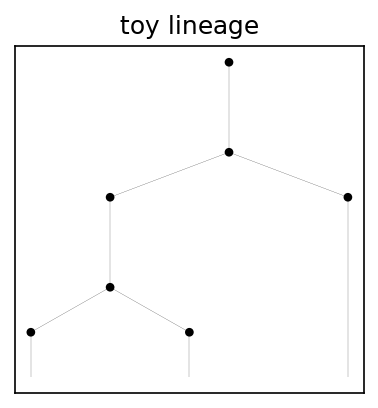

In [2]:
# a cell living 3 time points, dividing into two daughters,
# one of which divides again
successor = {
    0: [1], 1: [2], 2: [3, 10],
    3: [4], 4: [5], 5: [6, 20], 6: [7], 7: [], 20: [21], 21: [],
    10: [11], 11: [12], 12: [13], 13: [14], 14: [],
}
toy = LineageTree(
    successor=successor,
    pos={n: [n % 10, n // 10, 0] for n in successor},
    volume={n: 100 - n for n in successor},  # any property, as a dictionary
    name="toy",
)

print("roots:", sorted(toy.roots), " leaves:", sorted(toy.leaves))
print("time of each node:", dict(toy.time))
print("chains (cells):", toy.all_chains)
print("volume of node 12:", toy.volume[12])

fig, ax = toy.plot_subtree(0, figsize=(3, 3))
ax.set_title("toy lineage");

## 2. Loading data

`lineagetree` reads the outputs of the common tracking tools: one
`read_from_*` function per format, listed in `LOADERS`. `.lT` files, written
by `LineageTree.write`, are read with `LineageTree.load`.

In [3]:
for extension, loaders in lineagetree.LOADERS.items():
    print(f"{extension:9}", ", ".join(loader.__name__ for loader in loaders.values()))

bmf       read_from_bmf
csv       read_from_csv, read_from_mastodon_csv
binary    read_from_binary
xml       read_from_mamut_xml, read_from_ASTEC
mastodon  read_from_mastodon
pkl       read_from_ASTEC
txt       read_from_txt_for_celegans, read_from_txt_for_celegans_CAO, read_from_txt_for_celegans_BAO
swc       read_from_swc


test-mamut    2430 nodes, 6 roots, 18 chains, temporal: True
neuron         603 nodes, 1 roots, 80 chains, temporal: False


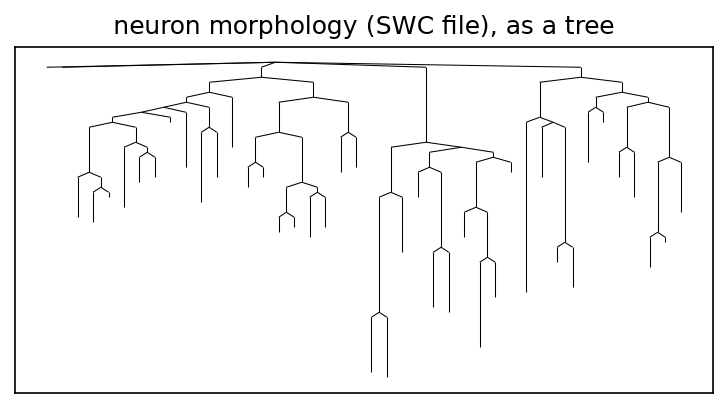

In [4]:
# the files used by the tests of the library
TEST_DATA = Path("../tests/data")
mamut = lineagetree.read_from_mamut_xml(TEST_DATA / "test-mamut.xml")
neuron = lineagetree.read_from_swc(TEST_DATA / "204-2-6nj.CNG.swc")
for lT in (mamut, neuron):
    print(
        f"{lT.name or 'neuron':12} {len(lT.nodes):5} nodes, {len(lT.roots)} roots, "
        f"{len(lT.all_chains)} chains, temporal: {lT.temporal}"
    )

# a neuron morphology is a tree too: its "time" is the depth of each point
fig, ax = neuron.plot_subtree(next(iter(neuron.roots)), figsize=(6, 3), size=0, lw=0.5)
ax.set_title("neuron morphology (SWC file), as a tree");

### The *C. elegans* embryo

Every cell has its standard name (AB, MS, E, ABala, …), stored as the label
of its nodes. The embryo is followed from the zygote P0 to about 360 cells.

The datasets of this notebook are listed in `data/datasets.json`, as
napari-relax lists its demo datasets: for each one, its file, its download
URL and its MD5 checksum. `fetch`, from the module `celegans_tools.py` next
to this notebook, downloads a dataset on first use, checks it, and keeps it
in `data/`. Besides this embryo, Part II uses two collections of the Bao
lab, 30 wild-type embryos and the 1,322 embryos of their RNAi screen, saved
as `LineageTreeManager` files (`.lTM`).

In [5]:
worm = LineageTree.load(ct.fetch("C.elegans"))
print(
    f"{worm.name}: {len(worm.nodes)} nodes, {len(worm.all_chains)} cells, "
    f"time points {worm.t_b}-{worm.t_e}, {len(worm.time_nodes[worm.t_e])} cells at the end"
)

WT-EMB08: 23954 nodes, 727 cells, time points 1-200, 360 cells at the end


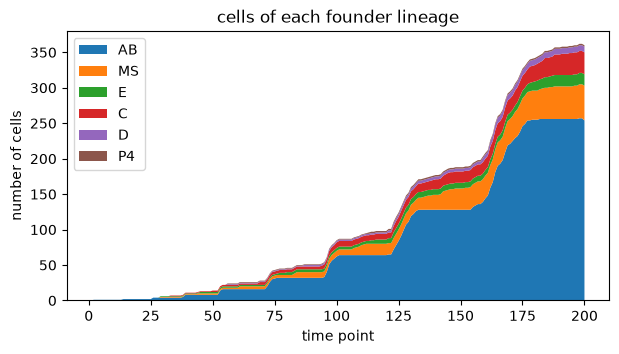

In [6]:
cell = ct.first_nodes(worm)  # name of each cell -> first node of its chain
FOUNDERS = ct.FOUNDERS  # the founder lineages, and their colours

# number of cells of each founder lineage over time
times = sorted(worm.time_nodes)
counts = {f: [] for f in FOUNDERS}
for t in times:
    per_founder = Counter(ct.founder_of(worm, n) for n in worm.time_nodes[t])
    for f in FOUNDERS:
        counts[f].append(per_founder[f])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.stackplot(times, *counts.values(), labels=FOUNDERS, colors=FOUNDERS.values())
ax.set(xlabel="time point", ylabel="number of cells", title="cells of each founder lineage")
ax.legend(loc="upper left");

## 3. Navigating the lineage

Nodes are integers; the methods take and return node ids. Here a few
questions about the cells of the embryo.

In [7]:
ABala = cell["ABala"]
chain = worm.get_chain_of_node(ABala)
print(f"ABala lives from time {worm.time[chain[0]]} to {worm.time[chain[-1]]} ({len(chain)} nodes)")
print("its daughters:", [worm.labels[d] for d in worm.successor[chain[-1]]])

# all its descendants, and those alive at a given time
descendants = worm.get_subtree_nodes(ABala)
print(f"its subtree: {len(descendants)} nodes, {len(worm.find_leaves(ABala))} leaves")
at_150 = worm.nodes_at_t(150, ABala)
print(f"descendants at time 150: {sorted(worm.labels[n] for n in at_150)}")

# ancestors
last_cell = next(iter(at_150))
print(f"ancestor of {worm.labels[last_cell]} at time 30:", worm.labels[worm.get_ancestor_at_t(last_cell, 30)])

# the path between two cells and their last common ancestor
path, ancestor = worm.get_shortest_path_and_last_common_ancestor(cell["ABalaa"], cell["MSaa"])
names = list(dict.fromkeys(worm.labels[n] for n in path))
print(f"ABalaa and MSaa: last common ancestor {worm.labels[ancestor]}, path through {names}")

ABala lives from time 39 to 53 (15 nodes)
its daughters: ['ABalap', 'ABalaa']
its subtree: 2017 nodes, 32 leaves
descendants at time 150: ['ABalaaaal', 'ABalaaaar', 'ABalaaapa', 'ABalaaapp', 'ABalaapaa', 'ABalaapap', 'ABalaappa', 'ABalaappp', 'ABalapaaa', 'ABalapaap', 'ABalapapa', 'ABalapapp', 'ABalappaa', 'ABalappap', 'ABalapppa', 'ABalapppp']
ancestor of ABalaaapp at time 30: ABal
ABalaa and MSaa: last common ancestor P0, path through ['ABalaa', 'ABala', 'ABal', 'ABa', 'AB', 'P0', 'P1', 'EMS', 'MS', 'MSa', 'MSaa']


## 4. Drawing lineages

`plot_subtree` draws the lineage spawned by a node, time running downwards;
nodes and edges can be coloured with dictionaries. Each cell is drawn from
its first node (its birth) to its last (its division).

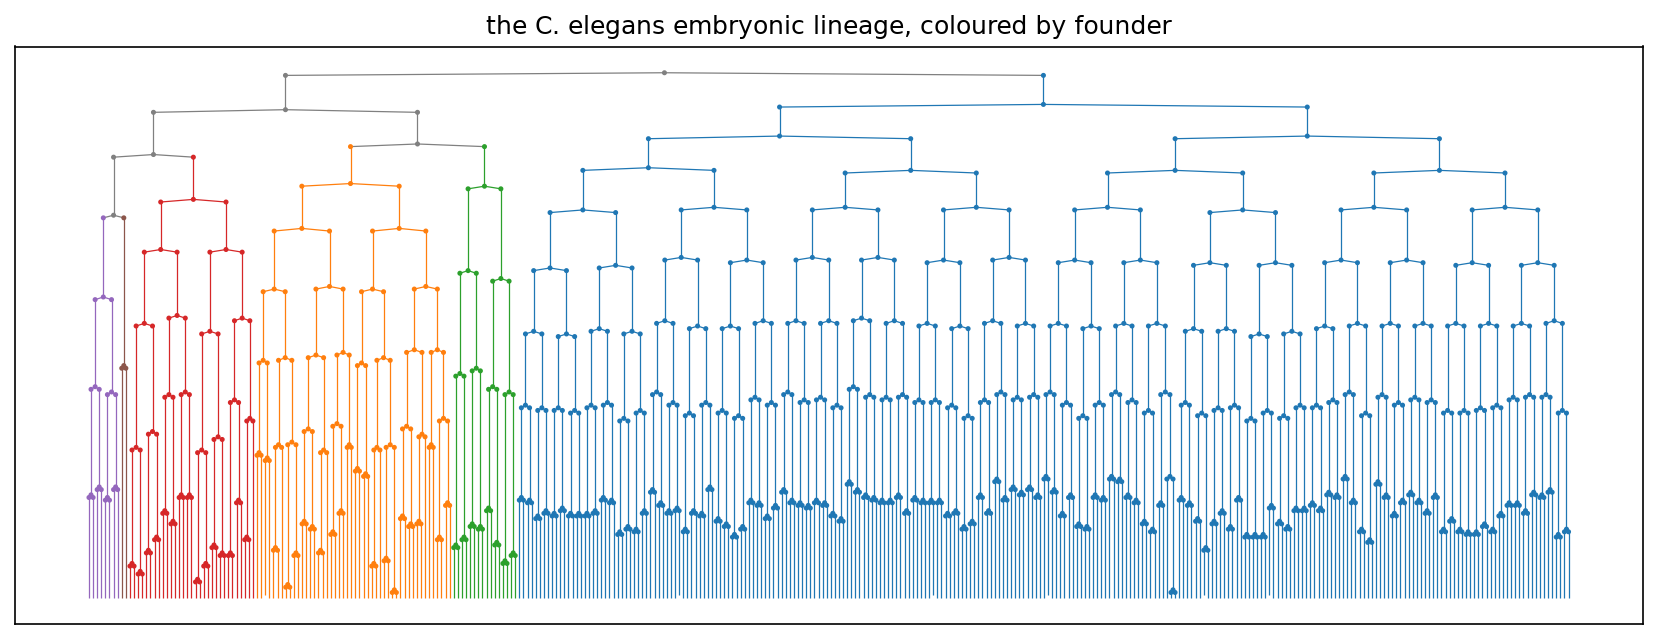

In [8]:
# colour each cell (its first and last node) by its founder lineage
colours = {}
for chain in worm.all_chains:
    colour = FOUNDERS.get(ct.founder_of(worm, chain[0]), "grey")
    colours[chain[0]] = colours[chain[-1]] = colour

fig, ax = worm.plot_subtree(
    cell["P0"], figsize=(14, 5), size=2, lw=0.6,
    color_of_nodes=colours, color_of_edges=colours,
)
ax.set_title("the C. elegans embryonic lineage, coloured by founder");

Lineages can also be summarised cell by cell. Below, every cell that is
born and divides during the recording, as a point: its time of birth
against the length of its cycle, coloured by founder lineage. A few cells
discussed in case study 11 are labelled. `plot_chain_histogram` draws the
distribution of these lengths.

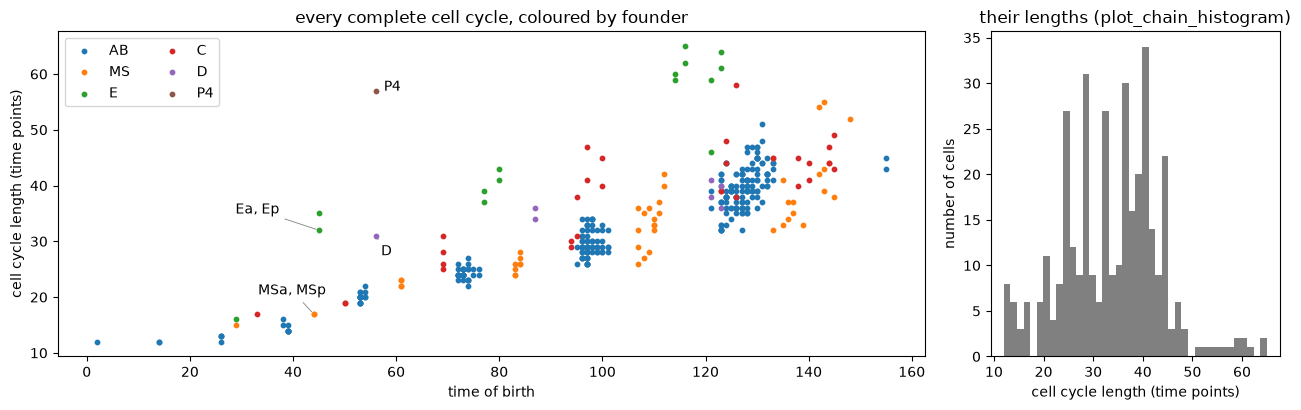

In [9]:
# every complete cell cycle: born and dividing during the recording
complete_cycles = [c for c in worm.all_chains if worm.predecessor[c[0]] and len(worm.successor[c[-1]]) == 2]

fig, (ax, ax_hist) = plt.subplots(1, 2, figsize=(13, 4.2), width_ratios=(3, 1))
for f, colour in FOUNDERS.items():
    chains = [c for c in complete_cycles if ct.founder_of(worm, c[0]) == f]
    ax.scatter([worm.time[c[0]] for c in chains], [len(c) for c in chains], s=10, color=colour, label=f)
for name, text, offset in (("Ea", "Ea, Ep", (-60, 12)), ("MSa", "MSa, MSp", (-40, 14)),
                           ("D", "D", (4, -14)), ("P4", "P4", (6, 0))):
    chain = worm.get_chain_of_node(cell[name])
    ax.annotate(text, (worm.time[chain[0]], len(chain)), xytext=offset, textcoords="offset points",
                arrowprops=dict(arrowstyle="-", color="grey", lw=0.6))
ax.set(xlabel="time of birth", ylabel="cell cycle length (time points)",
       title="every complete cell cycle, coloured by founder")
ax.legend(ncol=2)
worm.plot_chain_histogram(bins=40, color="grey", ax=ax_hist)
ax_hist.set(xlabel="cell cycle length (time points)", ylabel="number of cells",
            title="their lengths (plot_chain_histogram)")
fig.tight_layout();

## 5. Tissue reporters on the lineage

Any dictionary mapping nodes to values can be attached to the tree. This
embryo carries 104 of them, from an RNAi screen: each is the expression of
a tissue reporter, recorded in an embryo in which one gene was knocked down,
and mapped onto this embryo cell by cell. The name gives the gene and the
reporter: `GSK-3_PHA` is the pharynx reporter in a *gsk-3(RNAi)* embryo.
The reporters are *pha-4* for the pharynx (PHA; *pha-4* is also expressed
in the gut), *nhr-25* for the hypodermis, the skin of the worm (HYP), and
*cnd-1* for neurons (NEU). Values are NaN where the cell was not measured;
`gene_dict` maps the property names to the names of the conditions.

Averaging a condition over each cell and colouring the lineage shows which
sublineages express the reporter.

In [10]:
conditions = [name for name in worm.gene_dict if name in worm.__dict__]
reporters = Counter(worm.gene_dict[c].rsplit("_", 1)[1] for c in conditions)
print(f"{len(conditions)} conditions {dict(reporters)}, e.g. {[worm.gene_dict[c] for c in conditions[:4]]}")

# the condition whose values differ the most between founder lineages
condition = max(conditions, key=lambda c: ct.founder_contrast(worm, getattr(worm, c)))
print("most lineage-specific condition:", worm.gene_dict[condition])

104 conditions {'PHA': 33, 'NEU': 28, 'HYP': 43}, e.g. ['T11G6.8_PHA', 'MDT-6_NEU', 'F25B3.6_HYP', 'D1081.8_PHA']


most lineage-specific condition: Y48G10A.4_HYP


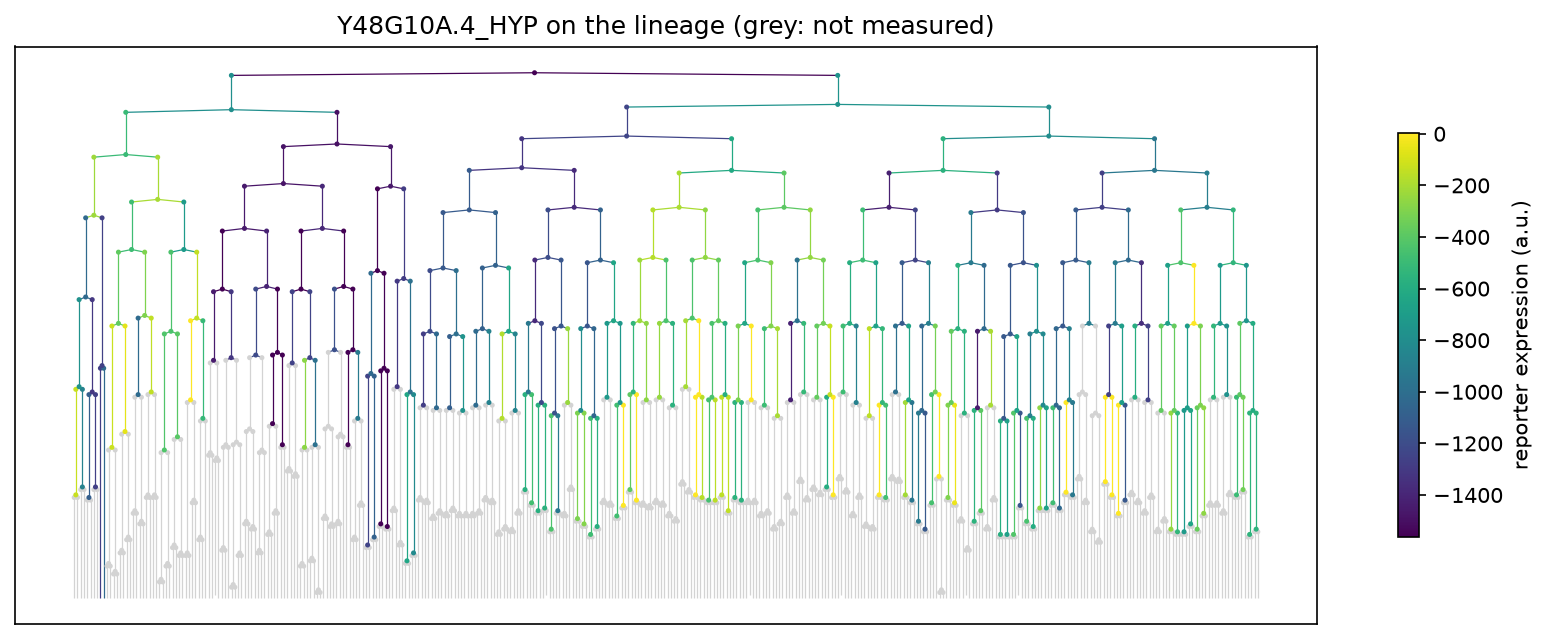

In [11]:
per_cell = ct.mean_per_cell(worm, getattr(worm, condition))  # mean of each cell
measured = np.array([v for v in per_cell.values() if not np.isnan(v)])
low, high = np.percentile(measured, [5, 95])
cmap = plt.get_cmap("viridis")

colours = {}
for chain in worm.all_chains:
    value = per_cell[chain[0]]
    colour = "lightgrey" if np.isnan(value) else cmap(np.clip((value - low) / (high - low), 0, 1))
    colours[chain[0]] = colours[chain[-1]] = colour

fig, ax = worm.plot_subtree(
    cell["P0"], figsize=(14, 5), size=2, lw=0.6,
    color_of_nodes=colours, color_of_edges=colours,
)
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(low, high)),
             ax=ax, label="reporter expression (a.u.)", shrink=0.7)
ax.set_title(f"{worm.gene_dict[condition]} on the lineage (grey: not measured)");

## 6. The embryo in space: neighbourhood graphs

With the positions of the cells, `lineagetree` builds spatial graphs among
the cells of each time point:

- `gabriel_graph`: two cells are neighbours if no other cell lies in the
  sphere whose diameter joins them, a good proxy for cell contacts;
- `k_nearest_neighbours`: the k closest cells, with their distances;
- `neighbours_in_radius` and `spatial_density`: the cells within a radius.

Here the embryo at the 188-cell stage, coloured by founder lineage, with
its Gabriel graph. The figure can be rotated.

In [12]:
gabriel = worm.gabriel_graph()  # all the time points

T = 150
nodes = sorted(worm.time_nodes[T])
xyz = np.array([worm.pos[n] for n in nodes])
traces = []
# edges of the Gabriel graph, as one line trace with breaks
edges = {tuple(sorted((a, b))) for a in nodes for b in gabriel.get(a, ())}
lines = [np.vstack([worm.pos[a], worm.pos[b], [np.nan] * 3]) for a, b in edges]
lines = np.vstack(lines)
traces.append(go.Scatter3d(x=lines[:, 0], y=lines[:, 1], z=lines[:, 2], mode="lines",
                           line=dict(color="lightgrey", width=2), name="Gabriel graph",
                           hoverinfo="skip"))
for f, colour in FOUNDERS.items():
    idx = [i for i, n in enumerate(nodes) if ct.founder_of(worm, n) == f]
    traces.append(go.Scatter3d(
        x=xyz[idx, 0], y=xyz[idx, 1], z=xyz[idx, 2], mode="markers", name=f,
        marker=dict(size=6, color=colour.replace("tab:", "")),
        text=[worm.labels[nodes[i]] for i in idx], hoverinfo="text",
    ))
fig = go.Figure(traces)
fig.update_layout(title=f"time {T}: {len(nodes)} cells, {len(edges)} Gabriel edges",
                  scene=dict(aspectmode="data"), height=600)
fig.show()

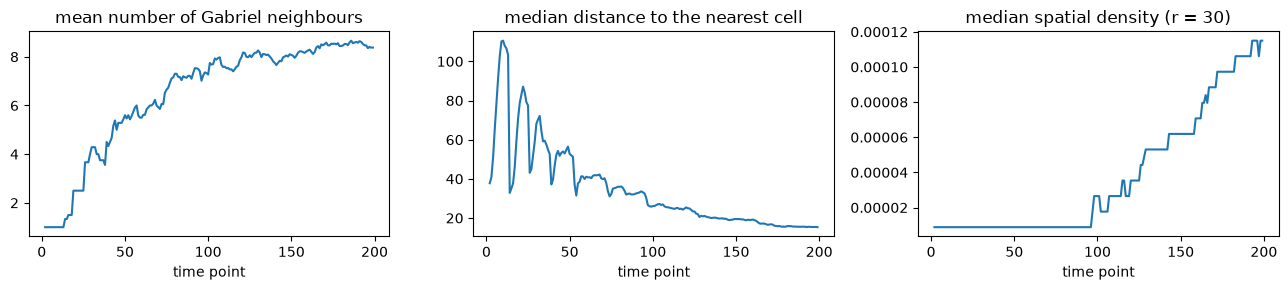

In [13]:
# how the neighbourhoods change during development
neighbours, distances = worm.k_nearest_neighbours(k=1)
density = worm.spatial_density(th=30)  # cells per unit volume within a radius of 30

times = sorted(worm.time_nodes)
# neighbours need two cells; the density is computed up to the last time point, excluded
times = [t for t in times if len(worm.time_nodes[t]) > 1 and t < worm.t_e]
degree = [np.mean([len(gabriel.get(n, ())) for n in worm.time_nodes[t]]) for t in times]
nearest = [np.median([distances[n][0] for n in worm.time_nodes[t]]) for t in times]
dens = [np.median([density[n] for n in worm.time_nodes[t]]) for t in times]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, values, title in zip(
    axes,
    (degree, nearest, dens),
    ("mean number of Gabriel neighbours", "median distance to the nearest cell", "median spatial density (r = 30)"),
    strict=True,
):
    ax.plot(times, values)
    ax.set(xlabel="time point", title=title)
fig.tight_layout();

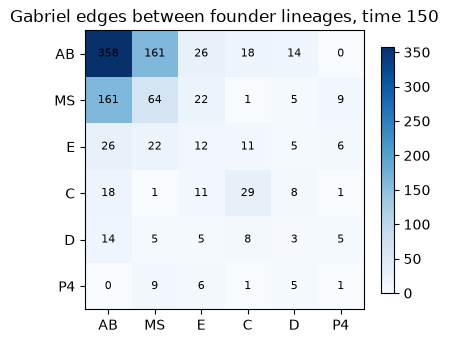

In [14]:
# which lineages touch each other? Gabriel edges between founders at time T
names = list(FOUNDERS)
contacts = np.zeros((len(names), len(names)))
for a, b in edges:
    fa, fb = ct.founder_of(worm, a), ct.founder_of(worm, b)
    if fa in FOUNDERS and fb in FOUNDERS:
        i, j = names.index(fa), names.index(fb)
        contacts[i, j] += 1
        contacts[j, i] += 1 if i != j else 0

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(contacts, cmap="Blues")
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, int(contacts[i, j]), ha="center", va="center", fontsize=8)
ax.set_title(f"Gabriel edges between founder lineages, time {T}")
fig.colorbar(im, ax=ax, shrink=0.8);

## 7. Cell trajectories and dynamic time warping

`dtw` compares the trajectories of two cells (their successive positions),
after aligning them in time and, by default, superimposing them with a
rigid transformation. The distance is the mean distance between aligned
positions, in the units of the positions.

ABplaa  vs ABpraa  DTW distance   4.17
ABplpa  vs ABprpa  DTW distance   7.08
ABplaa  vs MSaa    DTW distance   7.08
ABplaa  vs Caa     DTW distance   4.92


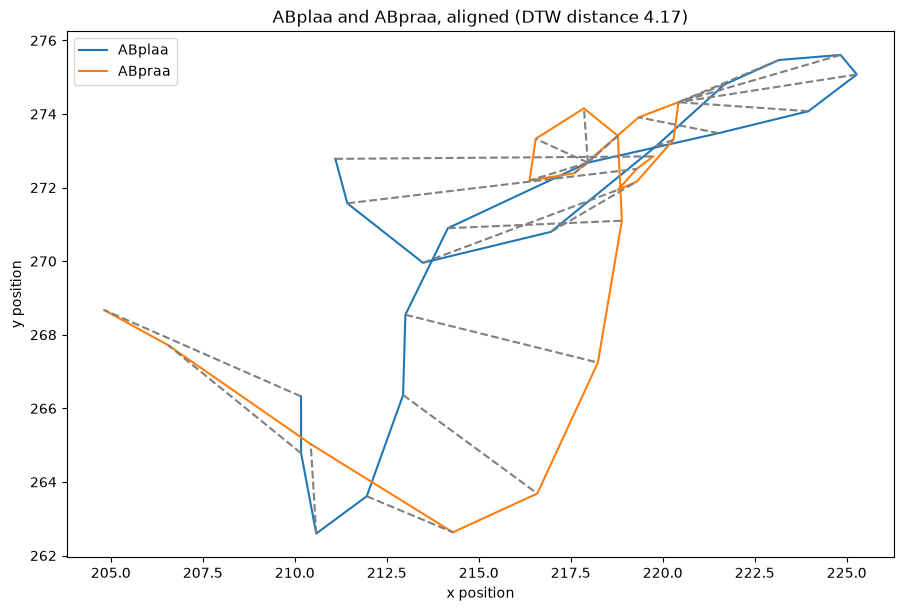

In [15]:
pairs = [("ABplaa", "ABpraa"), ("ABplpa", "ABprpa"), ("ABplaa", "MSaa"), ("ABplaa", "Caa")]
for a, b in pairs:
    distance, _ = worm.dtw(cell[a], cell[b])
    print(f"{a:7} vs {b:7} DTW distance {distance:6.2f}")

with warnings.catch_warnings():  # matplotlib: line colour given twice
    warnings.simplefilter("ignore", UserWarning)
    distance, fig = worm.plot_dtw_trajectory(
        cell["ABplaa"], cell["ABpraa"], projection="xy", alig=True
    )
ax = fig.axes[0]
ax.legend(ax.get_lines()[:2], ["ABplaa", "ABpraa"])
ax.set_title(f"ABplaa and ABpraa, aligned (DTW distance {distance:.2f})");

## 8. Comparing lineages with the unordered tree edit distance

The unordered tree edit distance (UTED) compares the shape and the timing
of two lineages: it is the cheapest way to turn one tree into the other by
matching, adding and removing cells, whatever the order of the daughters.
Trees are first simplified according to a **style**, from the fastest to
the most precise:

- `mini`: only the branching pattern;
- `simple`: one node per cell, weighted by its lifetime (the default);
- `normalized_simple`: like `simple`, with relative lifetime differences;
- `downsampled`: one node every few time points;
- `full`: every node.

By default the distance is normalised by the size of the larger tree.

In [16]:
import time

for style in ["mini", "simple", "normalized_simple", "downsampled", "full"]:
    start = time.perf_counter()
    d = worm.unordered_tree_edit_distance(cell["ABala"], cell["ABara"], style=style)
    print(f"{style:18} ABala vs ABara: {float(d):.3f}   ({time.perf_counter() - start:.2f} s)")

mini               ABala vs ABara: 0.000   (0.00 s)
simple             ABala vs ABara: 0.131   (0.00 s)
normalized_simple  ABala vs ABara: 0.068   (0.00 s)


downsampled        ABala vs ABara: 0.130   (0.14 s)


full               ABala vs ABara: 0.131   (0.53 s)


### Which lineages are alike?

At the 28-cell stage, every cell is the root of a lineage. Comparing all of
them pairwise (`unordered_tree_edit_distances_at_time_t`) and clustering
the distances groups lineages with similar division patterns and timing.

In [17]:
T28 = 70
worm.clear_comparisons()  # alignments are cached on the tree
roots = sorted(worm.time_nodes[T28], key=lambda n: worm.labels[n])
labels = [worm.labels[worm.get_chain_of_node(n)[0]] for n in roots]
with warnings.catch_warnings():  # the 378 alignments are cached: expected here
    warnings.filterwarnings("ignore", message="More than 100 comparisons")
    distances = worm.unordered_tree_edit_distances_at_time_t(T28, style="simple")
worm.clear_comparisons()

matrix = np.zeros((len(roots), len(roots)))
for (a, b), d in distances.items():
    i, j = roots.index(a), roots.index(b)
    matrix[i, j] = matrix[j, i] = d

order = leaves_list(linkage(squareform(matrix), method="average"))
fig = go.Figure(go.Heatmap(
    z=matrix[np.ix_(order, order)],
    x=[labels[i] for i in order], y=[labels[i] for i in order],
    colorscale="Viridis", colorbar=dict(title="UTED"),
))
fig.update_layout(title=f"UTED between the lineages of the {len(roots)} cells at time {T28}",
                  height=650, width=700, yaxis=dict(autorange="reversed"))
fig.show()

`labelled_mappings` gives the cells matched by the alignment, by name, and
the cells left without a partner. Here ABala and MSa: drawing both lineages
with their unmatched cells in red shows where their division patterns
differ.

47 matched cells, e.g. [('ABala', 'MSa'), ('ABalap', 'MSaa'), ('ABalapp', 'MSaaa'), ('ABalappp', 'MSaaaa')]
16 cells without a partner: ['ABalaaaarl', 'ABalaaaarr', 'ABalaapaaa', 'ABalaapaap', 'ABalaapapa', 'ABalaapapp', 'ABalaappaa', 'ABalaappap', 'ABalaapppa', 'ABalaapppp', 'ABalapaaaa', 'ABalapaaap', 'ABalapaapa', 'ABalapaapp', 'ABalappaaa', 'ABalappaap']


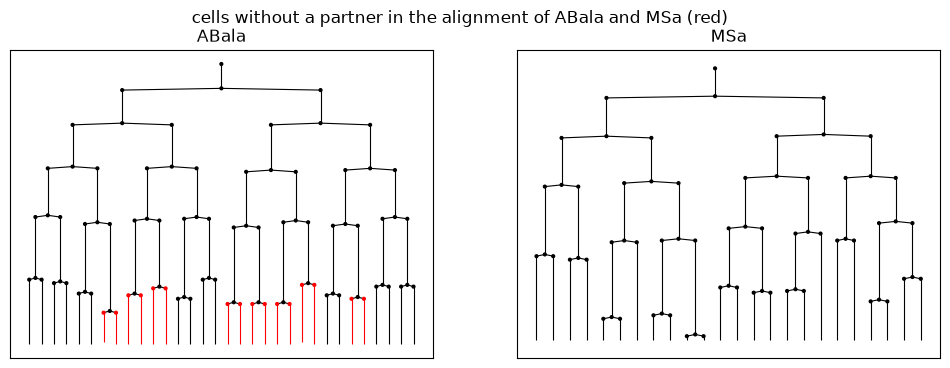

In [18]:
a, b = cell["ABala"], cell["MSa"]
mapping = worm.labelled_mappings(a, b, style="simple")
worm.clear_comparisons()
print(f"{len(mapping['matched'])} matched cells, e.g.", mapping["matched"][:4])
print(f"{len(mapping['unmatched'])} cells without a partner:", sorted(mapping["unmatched"]))

# colour the unmatched cells in red, from birth to division
unmatched = {cell[name] for name in mapping["unmatched"]}
colours = {}
for chain in worm.all_chains:
    if chain[0] in unmatched:
        colours[chain[0]] = colours[chain[-1]] = "red"

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for root, ax in zip((a, b), axes, strict=True):
    worm.plot_subtree(root, ax=ax, size=4, lw=0.8, color_of_nodes=colours,
                      color_of_edges=colours, default_color="black")
    ax.set_title(worm.labels[root])
fig.suptitle("cells without a partner in the alignment of ABala and MSa (red)");

## 9. Comparing embryos

A `LineageTreeManager` holds several embryos and compares lineages across
them with `cross_lineage_edit_distance`. Each tree needs a time resolution,
so that embryos recorded at different frame rates can be compared.

A manager can be saved to a `.lTM` file and loaded back, which is how the
30 wild-type embryos of the Bao lab are distributed. Here their MS
lineages, and the one of the embryo above, are compared over their first
80 time points.

In [19]:
wild_type_collection = LineageTreeManager.load(ct.fetch("C.elegans_wild_types"))
embryos = LineageTreeManager()
for name, lT in wild_type_collection:
    embryos.add(lT, name.replace("info_ZD_", "").replace("_edited", ""))  # shorter names
worm.time_resolution = 1
embryos.add(worm, worm.name)

CELL, DURATION = "MS", 80
roots, ends = {}, {}
for name, lT in embryos:
    lT.time_resolution = 1
    root = next(c[0] for c in lT.all_chains if lT.labels[c[0]] == CELL)
    roots[name], ends[name] = root, lT.time[root] + DURATION

names = list(roots)
matrix = np.zeros((len(names), len(names)))
with warnings.catch_warnings():  # the alignments are cached by the manager
    warnings.filterwarnings("ignore", message="More than 100 comparisons")
    for i, a in enumerate(names):
        for j, b in enumerate(names[i + 1:], i + 1):
            matrix[i, j] = matrix[j, i] = embryos.cross_lineage_edit_distance(
                roots[a], a, roots[b], b, ends[a], ends[b], style="simple"
            )
embryos.clear_comparisons()

order = leaves_list(linkage(squareform(matrix), method="average"))
fig = go.Figure(go.Heatmap(z=matrix[np.ix_(order, order)], x=[names[i] for i in order],
                           y=[names[i] for i in order], colorscale="Viridis", colorbar=dict(title="UTED")))
fig.update_layout(title=f"{CELL} lineages of {len(names)} wild-type embryos, first {DURATION} time points",
                  height=800, width=900, yaxis=dict(autorange="reversed"))
fig.show()

# do the distances follow the pace of development of the embryos (case study 22)?
wt_cycles = {name: ct.cycle_lengths(lT) for name, lT in embryos if name != worm.name}
wt_typical = ct.typical_cycles(wt_cycles)
wt_pace = {name: ct.pace(cycles, wt_typical) for name, cycles in wt_cycles.items()}
pairs = list(itertools.combinations(wt_pace, 2))
distance = np.array([matrix[names.index(a), names.index(b)] for a, b in pairs])
day = {name: next(p for p in name.split("_") if p.startswith("20")) for name in wt_pace}
same_day = np.array([day[a] == day[b] for a, b in pairs])
rho = spearmanr(distance, [abs(wt_pace[a] - wt_pace[b]) for a, b in pairs])[0]
print(f"rank correlation between the distance of two wild types and the difference of their paces: {rho:.2f}")
print(f"median distance, embryos imaged on the same day: {np.median(distance[same_day]):.2f}; "
      f"on different days: {np.median(distance[~same_day]):.2f}")

rank correlation between the distance of two wild types and the difference of their paces: 0.47
median distance, embryos imaged on the same day: 0.10; on different days: 0.16


The embryos fall into groups that partly follow the day they were imaged
(the date is in their names). Over a fixed number of time points, an
embryo that develops faster makes more divisions, and the pace of
development changes from one day to the next (case study 22): the distance
between two MS lineages grows with the difference of their paces, and two
embryos imaged on the same day are closer than two embryos imaged on
different days. `lineage_tree_examples.ipynb` matches the paces of two
embryos before comparing them.

For a detailed comparison of two embryos, cell by cell, see
`lineage_tree_examples.ipynb`, which locates a phenotype in the lineage and
in time.

## 10. Editing and saving

Trees can be cut, saved, edited and drawn. `get_subtree` makes a new tree
from a set of nodes; `write` saves a tree to a `.lT` file, read back with
`LineageTree.load`; `add_chain`, `add_root` and `remove_nodes` edit a tree
in place; `write_to_svg` draws it in a vector file.

ABala lineage: 2017 nodes, root ABala


saved and reloaded: True
after editing: 1041 nodes, last time point 210


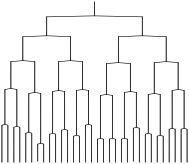

In [20]:
# the lineage of ABala alone, as a new tree, saved and read back
ABala_tree = worm.get_subtree(worm.get_subtree_nodes(cell["ABala"]))
print(f"ABala lineage: {len(ABala_tree.nodes)} nodes, root {ABala_tree.labels[next(iter(ABala_tree.roots))]}")

with tempfile.TemporaryDirectory() as folder:
    path = Path(folder) / "ABala.lT"
    ABala_tree.write(path)
    edited = LineageTree.load(path)
    print("saved and reloaded:", edited == ABala_tree)

    # remove the lineage of one granddaughter, and extend one leaf by 10 time points
    edited.remove_nodes(edited.get_subtree_nodes(cell["ABalaa"]))
    leaf = max(edited.leaves, key=edited.time.get)
    edited.add_chain(leaf, 10, downstream=True)
    print(f"after editing: {len(edited.nodes)} nodes, last time point {edited.t_e}")

    svg = Path(folder) / "ABala.svg"
    ABala_tree.write_to_svg(str(svg), vert_space_factor=1, horizontal_space=6)
    display(SVG(svg.read_text()))

# Part II. Case studies: biology from the lineage

Each case study asks a question about the embryo, answers it with a few
lines of `lineagetree`, and compares the answer with what is known of
*C. elegans* development. Times are in time points of the recording, and
distances in units of the typical spacing between neighbouring cells,
which shrinks as the cells divide.

The helpers called with `ct.` are in `celegans_tools.py`, next to this
notebook. A few shared variables first.

In [21]:
chain_of = {chain[0]: chain for chain in worm.all_chains}  # first node -> its chain
spacing = ct.cell_spacing(worm)  # time point -> typical distance between neighbouring cells

# the cells born and dividing during the recording: their cycles are complete
complete = [c for c in worm.all_chains if worm.predecessor[c[0]] and ct.divides(worm, c)]
print(f"{len(complete)} complete cell cycles, out of {len(worm.all_chains)} cells")
print(f"spacing between cells: {spacing[30]:.1f} at time 30, {spacing[worm.t_e]:.1f} at time {worm.t_e}")

362 complete cell cycles, out of 727 cells
spacing between cells: 68.2 at time 30, 15.4 at time 200


## 11. Each founder lineage has its own clock

Do all cells divide at the same pace? The point cloud of section 4 shows
every cell; here the cycles are grouped by founder lineage and by
generation (the number of divisions since the founder cell), with the
median and the interquartile range of each group.

median cell cycle length (time points), generation 0, 1, 2, ...
  AB    12   12   13   14   20   24   29   39   44
  MS    15   17   22   26   34   39
  E     16   34   40   60
  C     17   19   27   39   44
  D     31   35   39
  P4    57


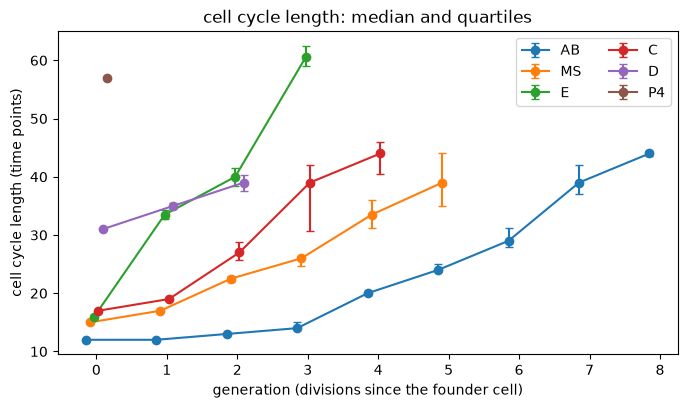

In [22]:
cycles = defaultdict(list)  # (founder, generation) -> cycle lengths
for chain in complete:
    name = worm.labels[chain[0]]
    if ct.founder(name) in FOUNDERS:
        cycles[ct.founder(name), ct.generation(name)].append(len(chain))

print("median cell cycle length (time points), generation 0, 1, 2, ...")
for f in FOUNDERS:
    gens = sorted(g for ff, g in cycles if ff == f)
    print(f"  {f:3}", " ".join(f"{np.median(cycles[f, g]):4.0f}" for g in gens))

fig, ax = plt.subplots(figsize=(8, 4.2))
for k, (f, colour) in enumerate(FOUNDERS.items()):
    gens = np.array(sorted(g for ff, g in cycles if ff == f))
    low, median, high = np.array([np.percentile(cycles[f, g], [25, 50, 75]) for g in gens]).T
    ax.errorbar(gens + 0.06 * (k - 2.5), median, yerr=[median - low, high - median], fmt="o-",
                color=colour, capsize=3, label=f)
ax.set(xlabel="generation (divisions since the founder cell)", ylabel="cell cycle length (time points)",
       title="cell cycle length: median and quartiles")
ax.legend(ncol=2);

Each founder lineage keeps its own pace. AB is the fastest at every
generation, MS and C come next, E and D are slower, and P4 is the slowest:
it divides only once, into Z2 and Z3, the precursors of the germline, which
then stay quiescent until the larva hatches. Within a lineage, cycles
lengthen at each generation, slowly at first in AB (12 to 14 time points
over four generations), then faster (20, 24, 29 and 39).

The E lineage stands out at its second generation: Ea and Ep take twice as
long as their MS cousins to divide (34 time points against 17). It is
during this long cycle that they move into the embryo, the first step of
gastrulation (case study 16). [Bao et al. (2008)](https://doi.org/10.1016/j.ydbio.2008.02.054)
found the same hierarchy: the pace is first set by the founder lineage,
then tuned by tissue.

## 12. The AB cells divide in synchrony, then drift apart

AB divides into ABa and ABp, which divide at the same time, and so do
their four daughters. For how many rounds does this last? Here the time
of every AB division (the last node of each chain), by generation and by
sublineage.

generation  cells  spread   mean time of division in ABal  ABar  ABpl  ABpr
         0      1       0                             -     -     -     -
         1      2       0                             -     -     -     -
         2      4       1                          38.0  38.0  38.0  37.0
         3      8       1                          52.5  52.0  52.0  52.5
         4     16       4                          72.5  72.5  71.2  73.0
         5     32       6                          97.5  96.0  95.4  97.5
         6     64      12                         127.1 125.9 124.4 127.5
         7    128      27                         166.4 166.4 163.1 167.3
         8      2       2                         198.0     -     -     -


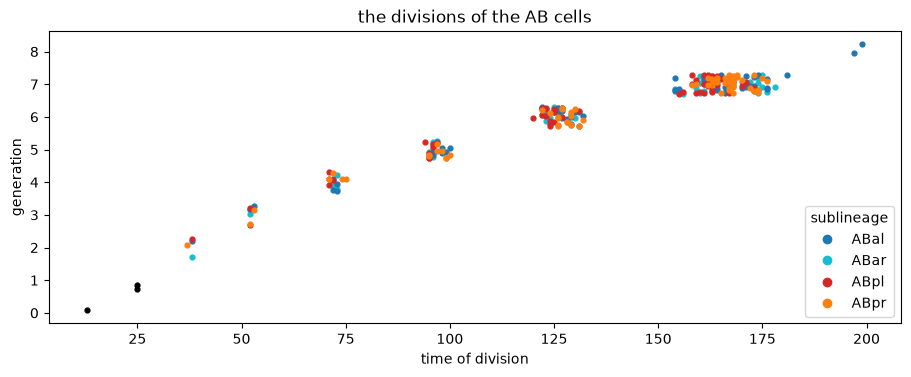

In [23]:
QUARTERS = {"ABal": "tab:blue", "ABar": "tab:cyan", "ABpl": "tab:red", "ABpr": "tab:orange"}
division = defaultdict(lambda: defaultdict(list))  # generation -> sublineage -> times
for chain in complete:
    name = worm.labels[chain[0]]
    if ct.founder(name) == "AB":
        division[ct.generation(name)][name[:4]].append(worm.time[chain[-1]])

rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(11, 3.8))
for g, by_quarter in division.items():
    for quarter, times in by_quarter.items():
        ax.scatter(times, g + rng.uniform(-0.3, 0.3, len(times)), s=12, color=QUARTERS.get(quarter, "black"))
ax.set(xlabel="time of division", ylabel="generation", title="the divisions of the AB cells")
ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", color=c, label=q) for q, c in QUARTERS.items()],
          title="sublineage", loc="lower right")

print("generation  cells  spread   mean time of division in ABal  ABar  ABpl  ABpr")
for g in sorted(division):
    times = [t for ts in division[g].values() for t in ts]
    means = " ".join(f"{np.mean(division[g][q]):5.1f}" if q in division[g] else "    -" for q in QUARTERS)
    print(f"{g:10} {len(times):6} {max(times) - min(times):7}   {means:>45}")

The first four rounds are synchronous to within one time point. Then the
spread grows at each round: 4, 6, 12 and 27 time points. The divisions
drift apart, but not at random: [Bao et al. (2008)](https://doi.org/10.1016/j.ydbio.2008.02.054)
showed that the order of the divisions is the same in every embryo, and
tied to the fate of the cells. In this embryo, the ABpl cells divide a
little before their ABpr homologues from generation 4 on; case study 22
checks it in 30 embryos.

### Is the drift just noise?

If each cell cycle had a small random error, independent from one cell to
the next, the errors would add up along the lineage, and the divisions
would drift apart even if every cell followed the same program. The
observed spread of the division times (their standard deviation in each
generation) can be compared with what such noise would give:

- **constant noise**: every cycle has the same error, here the spread of the
  cycle lengths at generation 2; the spread of the division times then
  grows as the square root of the number of generations;
- **proportional noise**: the error is a fixed fraction of the cycle length
  (the coefficient of variation of generations 2 to 5), so it grows as the
  cycles lengthen;
- **independent cycles**: the spreads of the cycle lengths measured at each
  generation in this embryo, added up as if mothers and daughters were
  independent.

spread of the division times: 0.0 0.4 0.4 1.1 1.5 2.9 5.9 (generations 1 to 7)
spread of the cycle lengths:  0.0 0.4 0.7 0.8 1.0 2.3 3.8
correlation between the cycle of a cell and that of its mother: 0.55 (252 pairs)


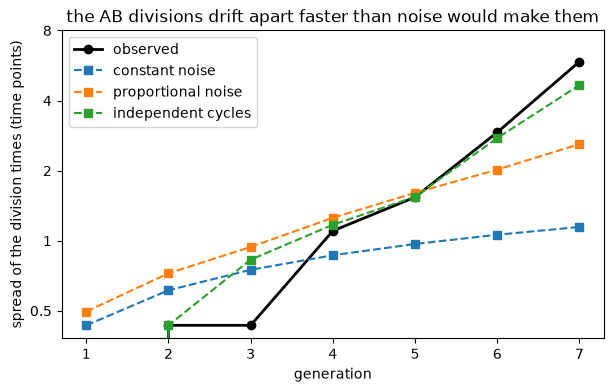

In [24]:
by_generation = defaultdict(list)  # generation -> (name, cycle length, time of division)
for chain in complete:
    name = worm.labels[chain[0]]
    if ct.founder(name) == "AB" and 1 <= ct.generation(name) <= 7:
        by_generation[ct.generation(name)].append((name, len(chain), worm.time[chain[-1]]))
gens = sorted(by_generation)
observed = np.array([np.std([t for _, _, t in by_generation[g]]) for g in gens])
cycle_mean = np.array([np.mean([c for _, c, _ in by_generation[g]]) for g in gens])
cycle_var = np.array([np.var([c for _, c, _ in by_generation[g]]) for g in gens])

sigma = np.sqrt(cycle_var[gens.index(2)])
cv = np.mean([np.sqrt(cycle_var[gens.index(g)]) / cycle_mean[gens.index(g)] for g in (2, 3, 4, 5)])
models = {
    "constant noise": sigma * np.sqrt(np.arange(1, len(gens) + 1)),
    "proportional noise": cv * np.sqrt(np.cumsum(cycle_mean**2)),
    "independent cycles": np.sqrt(np.cumsum(cycle_var)),
}

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(gens, observed, "o-", color="black", lw=2, label="observed")
for (label, values), colour in zip(models.items(), ("tab:blue", "tab:orange", "tab:green"), strict=True):
    ax.plot(gens, values, "s--", color=colour, label=label)
ax.set(xlabel="generation", ylabel="spread of the division times (time points)", yscale="log",
       title="the AB divisions drift apart faster than noise would make them")
ax.set_yticks([0.5, 1, 2, 4, 8], ["0.5", "1", "2", "4", "8"])
ax.minorticks_off()
ax.legend()

# is the delay of a cell inherited? its cycle against its mother's, both relative to their generation
residual = {}
for g in gens:
    mean = np.mean([c for _, c, _ in by_generation[g]])
    residual.update({name: c - mean for name, c, _ in by_generation[g]})
pairs = [(residual[name[:-1]], residual[name]) for name in residual if name[:-1] in residual]
print("spread of the division times:", " ".join(f"{s:.1f}" for s in observed), "(generations 1 to 7)")
print("spread of the cycle lengths: ", " ".join(f"{np.sqrt(v):.1f}" for v in cycle_var))
mother_cycle, own_cycle = np.array(pairs).T
print(f"correlation between the cycle of a cell and that of its mother: "
      f"{np.corrcoef(mother_cycle, own_cycle)[0, 1]:.2f} ({len(pairs)} pairs)")

Noise of either kind falls far short: by generation 7 the divisions are
spread over 5.9 time points (standard deviation), while constant or
proportional noise would give 1.1 to 2.6. The cycle lengths themselves
spread out from one generation to the next (from 0.4 to 3.8 time points),
and the deviations are inherited: a cell whose cycle is long tends to have
daughters whose cycles are long too (r = 0.55), so that at generation 7
the observed spread exceeds even the independent-cycles curve. This looks
like a program rather than noise, and case study 22 confirms it in 30
embryos: from generation 6 on, most of the asynchrony is the same in every
embryo.

## 13. Sisters are not equal

When a cell divides along the anterior–posterior axis, its daughters are
named *a* and *p*. Anterior and posterior sisters are different cells: the
Wnt/β-catenin asymmetry pathway makes them so at nearly every a/p division
([Meneghini et al. 1999](https://doi.org/10.1038/21666)). Do they divide at
the same time? For every pair of a/p sisters that both divide, which one
divides first?

AB, generations 1-5    29 pairs: p first  31%, a first  24%, mean cycle(p) - cycle(a) -0.1
AB, generation 6       32 pairs: p first  81%, a first  12%, mean cycle(p) - cycle(a) -2.3
AB, generation 7       63 pairs: p first  63%, a first  27%, mean cycle(p) - cycle(a) -1.6
MS                     21 pairs: p first  14%, a first  76%, mean cycle(p) - cycle(a) +4.0
C                      14 pairs: p first  21%, a first  64%, mean cycle(p) - cycle(a) +0.4


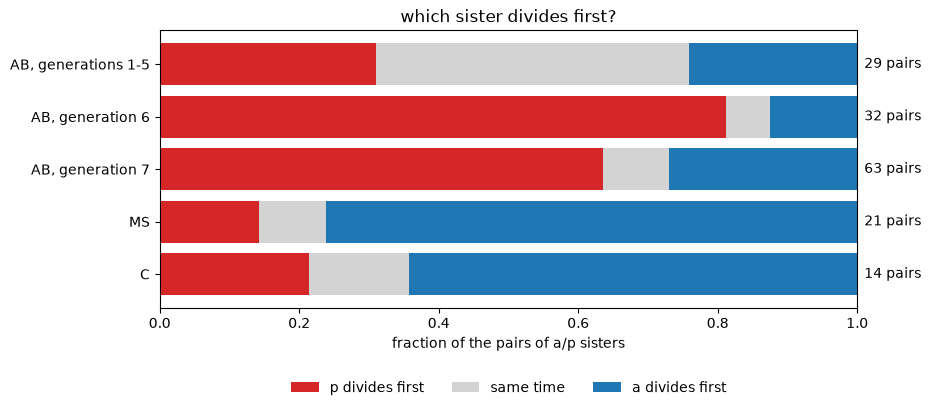

In [25]:
pace = defaultdict(list)  # (founder, generation of the sisters) -> cycle(p) - cycle(a)
for chain in worm.all_chains:
    if not ct.divides(worm, chain):
        continue
    sisters = {name[-1]: c for name, c in ct.daughters(worm, chain).items()}
    if set(sisters) == {"a", "p"} and all(ct.divides(worm, c) for c in sisters.values()):
        name = worm.labels[sisters["a"][0]]
        pace[ct.founder(name), ct.generation(name)].append(len(sisters["p"]) - len(sisters["a"]))

groups = {
    "AB, generations 1-5": [d for (f, g), v in pace.items() if f == "AB" and g <= 5 for d in v],
    "AB, generation 6": pace["AB", 6],
    "AB, generation 7": pace["AB", 7],
    **{f: [d for (ff, _), v in pace.items() if ff == f for d in v] for f in ("MS", "C", "E", "D")},
}
groups = {group: values for group, values in groups.items() if len(values) >= 10}

fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (group, values) in enumerate(groups.items()):
    values = np.array(values)
    left = 0
    for share, colour, label in zip(
        (np.mean(values < 0), np.mean(values == 0), np.mean(values > 0)),
        ("tab:red", "lightgrey", "tab:blue"),
        ("p divides first", "same time", "a divides first"),
        strict=True,
    ):
        ax.barh(i, share, left=left, color=colour, label=label if i == 0 else None)
        left += share
    ax.text(1.01, i, f"{len(values)} pairs", va="center")
    print(f"{group:20} {len(values):4} pairs: p first {np.mean(values < 0):4.0%}, "
          f"a first {np.mean(values > 0):4.0%}, mean cycle(p) - cycle(a) {values.mean():+.1f}")
ax.set_yticks(range(len(groups)), list(groups))
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="fraction of the pairs of a/p sisters", title="which sister divides first?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False);

In AB, the posterior sister usually divides first, from generation 6 on.
In MS it is the other way round: the anterior sister divides first in
three quarters of the pairs. The difference is one or two time points in
AB and four in MS. Case study 22 shows that both biases are found in every
embryo.

## 14. Cell names follow the body axes

Sulston named the daughters of a cell by their positions after the
division: anterior/posterior (a/p), left/right (l/r) or dorsal/ventral
(d/v). The positions let us check these names. `ct.body_axes`
gives the axes of the embryo at any time point: the anterior–posterior axis
is its long axis, pointing to the ABa side, and the left–right axis goes
from the ABpl to the ABpr cells. The direction of a division is the vector
between the two daughters, two time points after their birth, compared with
the axes of that time point. The embryo turns around its long axis during
the recording, so the axes have to be taken at the time of each division.

a/p: 342 divisions, mean |cos| with the axes anterior–posterior 0.80, left–right 0.30, dorsal–ventral 0.32
l/r: 6 divisions, mean |cos| with the axes anterior–posterior 0.28, left–right 0.72, dorsal–ventral 0.53
d/v: 2 divisions, mean |cos| with the axes anterior–posterior 0.75, left–right 0.43, dorsal–ventral 0.49
a/p divisions: the a daughter is anterior in 98% of them
l/r divisions: the r daughter is on the right in 6 of 6


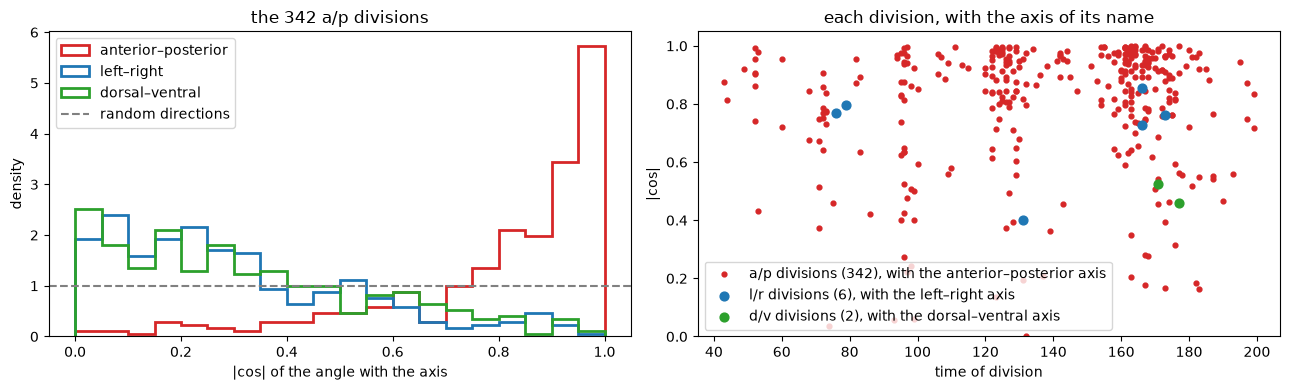

In [26]:
axes_at = {t: ct.body_axes(worm, t) for t in worm.time_nodes if t >= 40}
division_axes = defaultdict(list)  # kind -> (time, cos with the AP, LR and DV axes)
for chain in worm.all_chains:
    t = worm.time[chain[-1]]
    if not ct.divides(worm, chain) or t < 40:  # the left-right axis needs the ABpl and ABpr lineages
        continue
    (name1, chain1), (name2, chain2) = sorted(ct.daughters(worm, chain).items())
    kind = name1[-1] + "/" + name2[-1]
    if kind in ("a/p", "l/r", "d/v"):
        v = ct.position_after(worm, chain2) - ct.position_after(worm, chain1)  # from a to p, from l to r...
        _, ap, lr, dv = axes_at[min(t + 2, worm.t_e)]
        division_axes[kind].append((t, np.array([ap, lr, dv]) @ v / np.linalg.norm(v)))

AXES = ["anterior–posterior", "left–right", "dorsal–ventral"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
cosines = np.array([c for _, c in division_axes["a/p"]])
for i, colour in enumerate(("tab:red", "tab:blue", "tab:green")):
    ax1.hist(np.abs(cosines[:, i]), bins=20, range=(0, 1), density=True, histtype="step",
             lw=2, color=colour, label=AXES[i])
ax1.axhline(1, color="grey", ls="--", label="random directions")
ax1.set(xlabel="|cos| of the angle with the axis", ylabel="density",
        title=f"the {len(cosines)} a/p divisions")
ax1.legend(loc="upper left")
for i, (kind, colour) in enumerate((("a/p", "tab:red"), ("l/r", "tab:blue"), ("d/v", "tab:green"))):
    times, c = zip(*division_axes[kind], strict=True)
    ax2.scatter(times, np.abs(np.array(c)[:, i]), s=12 if kind == "a/p" else 40, color=colour,
                label=f"{kind} divisions ({len(times)}), with the {AXES[i]} axis")
ax2.set(xlabel="time of division", ylabel="|cos|", ylim=(0, 1.05),
        title="each division, with the axis of its name")
ax2.legend(loc="lower left")
fig.tight_layout()

for kind, items in division_axes.items():
    c = np.array([x for _, x in items])
    print(f"{kind}: {len(c)} divisions, mean |cos| with the axes "
          + ", ".join(f"{name} {v:.2f}" for name, v in zip(AXES, np.abs(c).mean(axis=0), strict=True)))
print(f"a/p divisions: the a daughter is anterior in {np.mean(cosines[:, 0] < 0):.0%} of them")
lr_cos = np.array([c[1] for _, c in division_axes["l/r"]])
print(f"l/r divisions: the r daughter is on the right in {np.sum(lr_cos > 0)} of {len(lr_cos)}")

Nearly all the divisions are a/p divisions, and their names are right: the
*a* daughter is anterior to its sister in 98% of them, and the division
follows the long axis of the embryo (mean |cos| 0.80, against 0.5 for
random directions). The l/r divisions follow the left–right axis, with the
*r* daughter always on the right; the two d/v divisions, at the end of the
recording, are oblique. Because most divisions are a/p, a single
anterior–posterior mechanism, the Wnt/β-catenin asymmetry pathway, can tell
sisters apart at nearly every division (case study 13).

## 15. The contacts behind the first inductions

Early *C. elegans* cells instruct the neighbours they touch. At the 4-cell
stage, P2 signals to ABp through Notch, which makes ABp different from its
sister ABa, the one that does not touch P2; P2 also signals to EMS through
Wnt, which makes the posterior daughter of EMS, E, produce the gut. At the
12-cell stage, MS signals through Notch to the two granddaughters of ABa it
touches, which then make pharynx ([Priess 2005](https://doi.org/10.1895/wormbook.1.4.1)).

Does the Gabriel graph find these contacts? For each stage, the fraction of
its time points during which two cells are Gabriel neighbours. In the
figure, each cell sits at its mean position during the stage, projected on
the plane that spreads the cells best (anterior to the left), and the width
of a line is the fraction of the stage the two cells spend in contact.

4-cell stage, fraction of the stage in contact:
  ABa-ABp 1.0
  ABa-EMS 0.7
  ABp-EMS 1.0
  ABp-P2 0.7
  EMS-P2 1.0
12-cell stage, contact with MS: ABala 0.0, ABalp 1.0, ABara 1.0, ABarp 0.6, ABpla 0.6, ABplp 1.0, ABpra 0.2, ABprp 1.0


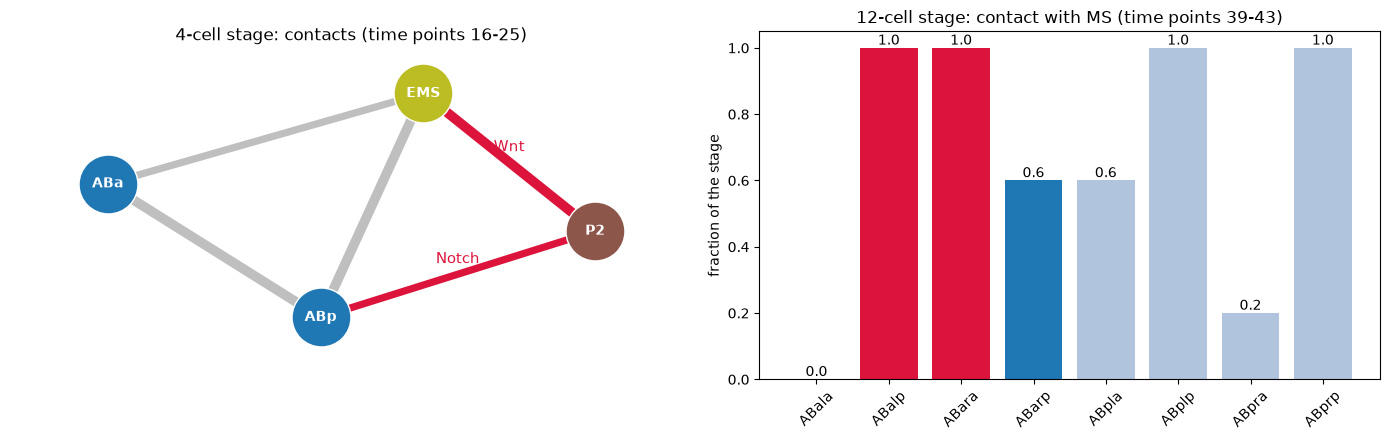

In [27]:
stage_times = ct.stage_times(worm)  # number of cells -> time points
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), width_ratios=(1.1, 1))

# the 4-cell stage: every contact, the signalling ones in red
SIGNALS = {("ABp", "P2"): "Notch", ("EMS", "P2"): "Wnt"}
COLOURS = {"ABa": "tab:blue", "ABp": "tab:blue", "EMS": "tab:olive", "P2": "tab:brown"}
xy = ct.stage_layout(worm, stage_times[4])
four = ct.contact_frequency(worm, gabriel, stage_times[4])
for (a, b), f in four.items():
    signal = SIGNALS.get((a, b))
    ax1.plot(*zip(xy[a], xy[b], strict=True), lw=1 + 6 * f, zorder=1,
             color="crimson" if signal else "grey", alpha=1 if signal else 0.5)
    if signal:
        ax1.annotate(signal, np.mean([xy[a], xy[b]], axis=0), color="crimson", fontsize=11,
                     ha="center", xytext=(0, 8), textcoords="offset points")
for name, (x, y) in xy.items():
    ax1.scatter(x, y, s=1800, zorder=2, edgecolor="white", color=COLOURS[name])
    ax1.text(x, y, name, ha="center", va="center", color="white", fontweight="bold", zorder=3)
ax1.set_title(f"4-cell stage: contacts (time points {stage_times[4][0]}-{stage_times[4][-1]})")
ax1.set_aspect("equal")
ax1.margins(0.2)
ax1.axis("off")

# the 12-cell stage: which AB cells does MS touch?
twelve = ct.contact_frequency(worm, gabriel, stage_times[12])
ab_cells = sorted(name for pair in twelve for name in pair if name.startswith("AB"))
ab_cells = list(dict.fromkeys(ab_cells))
with_ms = [twelve.get(tuple(sorted((name, "MS"))), 0) for name in ab_cells]
bars = ax2.bar(ab_cells, with_ms, color=["crimson" if name in ("ABalp", "ABara") else
                                         "tab:blue" if name.startswith("ABa") else "lightsteelblue"
                                         for name in ab_cells])
ax2.set(ylabel="fraction of the stage", ylim=(0, 1.05),
        title=f"12-cell stage: contact with MS (time points {stage_times[12][0]}-{stage_times[12][-1]})")
ax2.bar_label(bars, fmt="%.1f")
ax2.tick_params(axis="x", rotation=45)
fig.tight_layout()

print("4-cell stage, fraction of the stage in contact:")
for (a, b), f in sorted(four.items()):
    print(f"  {a}-{b} {f:.1f}")
print("12-cell stage, contact with MS:", ", ".join(f"{n} {f:.1f}" for n, f in zip(ab_cells, with_ms, strict=True)))

The graph recovers the contacts of the textbook. At the 4-cell stage, P2
touches EMS during the whole stage and ABp during most of it, but never
ABa. At the 12-cell stage, MS touches two of the four granddaughters of
ABa, ABalp and ABara (in red), during the whole stage, ABarp during part of
it and ABala never. The cells that P2 and MS induce are the ones they
touch: ABp at the 4-cell stage, ABalp and ABara at the 12-cell stage, and
case study 18 shows that ABalp and ABara do make pharynx. MS also touches
two granddaughters of ABp (light blue), which make no pharynx: contact is
needed for the induction, but it is not the only condition.

## 16. Gastrulation: who moves inside, and when

Gastrulation starts when the two E cells, the gut precursors, move from the
surface into the embryo. Other cells follow, at times set by their fate
([Nance & Priess 2002](https://doi.org/10.1242/dev.129.2.387)). How deep is
each cell? Its depth is its distance to the surface of the embryo (the
convex hull of the cells of its time point), in units of the spacing
between cells.

first time point from which the median depth stays above one cell:
  AB  never
  MS  128
  E   97
  C   200
  D   143
  P4  140


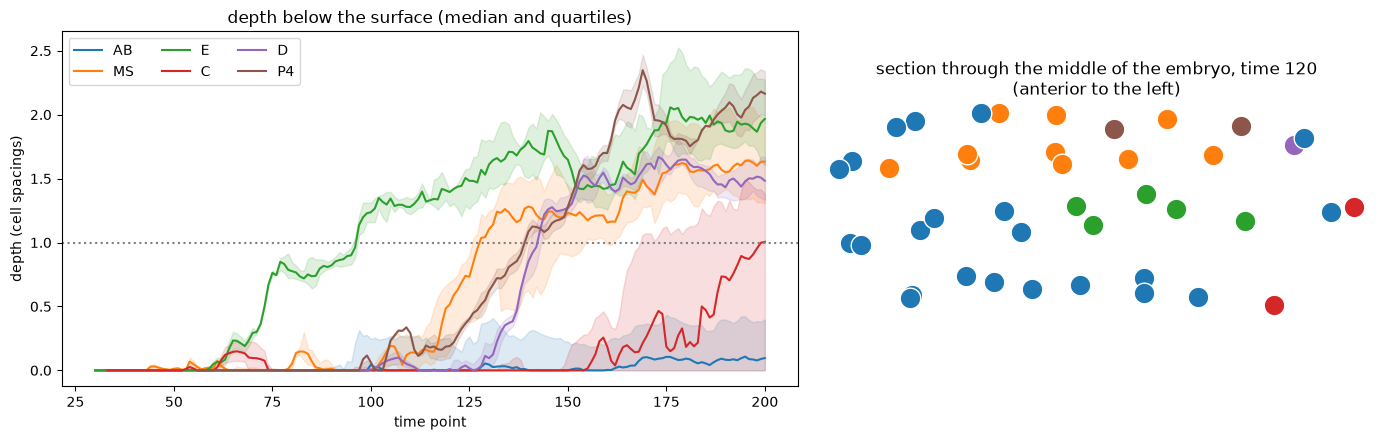

In [28]:
depth = ct.surface_depth(worm, spacing)  # node -> distance to the surface, in cell spacings

times = sorted(t for t in worm.time_nodes if t >= 30)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), width_ratios=(1.3, 1))
print("first time point from which the median depth stays above one cell:")
for f, colour in FOUNDERS.items():
    per_time = {t: [depth[n] for n in worm.time_nodes[t] if ct.founder_of(worm, n) == f] for t in times}
    ts = [t for t in times if per_time[t]]
    low, median, high = np.array([np.percentile(per_time[t], [25, 50, 75]) for t in ts]).T
    ax1.plot(ts, median, color=colour, label=f)
    ax1.fill_between(ts, low, high, color=colour, alpha=0.15)
    inside = [t for i, t in enumerate(ts) if (median[i:] > 1).all()]
    print(f"  {f:3} {inside[0] if inside else 'never'}")
ax1.axhline(1, color="grey", ls=":")
ax1.set(xlabel="time point", ylabel="depth (cell spacings)",
        title="depth below the surface (median and quartiles)")
ax1.legend(ncol=3)

# a section through the middle of the embryo, at time T_SECTION
T_SECTION = 120
centre, ap, lr, dv = ct.body_axes(worm, T_SECTION)
for n in worm.time_nodes[T_SECTION]:
    p = np.asarray(worm.pos[n]) - centre
    if abs(p @ lr) < spacing[T_SECTION]:  # cells within one spacing of the midplane
        ax2.scatter(-(p @ ap), p @ dv, s=220, color=FOUNDERS.get(ct.founder_of(worm, n), "grey"), edgecolor="white")
ax2.set_aspect("equal")
ax2.set_title(f"section through the middle of the embryo, time {T_SECTION}\n(anterior to the left)")
ax2.axis("off")
fig.tight_layout();

E goes first: its cells leave the surface from about time 60 and stay more
than one cell deep from time 97. MS follows (from time 128), then P4 and D
(140 and 143), then part of C at the end of the recording, while AB stays
at the surface. In the section, the E cells form the core of the embryo.
This is the order seen under the microscope: the gut first, then the
mesoderm and the germline precursors.

## 17. Left and right become mirror images

The worm is bilaterally symmetric, but its early embryo is not obviously
so: the left and right cells are born at skewed positions. The ABpl and
ABpr lineages make mirror-image sets of cells on the two sides: ABplaaa on
the left has a homologue, ABpraaa, on the right. When do their positions
become mirror images?

A first guess for the mirror is the sagittal plane of the body: through
the centre of the embryo, containing its long axis, perpendicular to the
left–right axis. Reflect each ABpr cell through it, and measure how far
each ABpl cell is from the reflection of its homologue, and from the
reflections of the other ABpr cells.

shift of the mirrored ABpr cells from their ABpl homologues along the anterior-posterior axis
(cell spacings, negative: posterior)
  time 60: -1.5, posterior for 100% of the 4 pairs
  time 100: -3.7, posterior for 100% of the 14 pairs
  time 140: -1.9, posterior for 100% of the 32 pairs
  time 180: -0.4, posterior for 80% of the 64 pairs
  time 200: -0.3, posterior for 81% of the 62 pairs


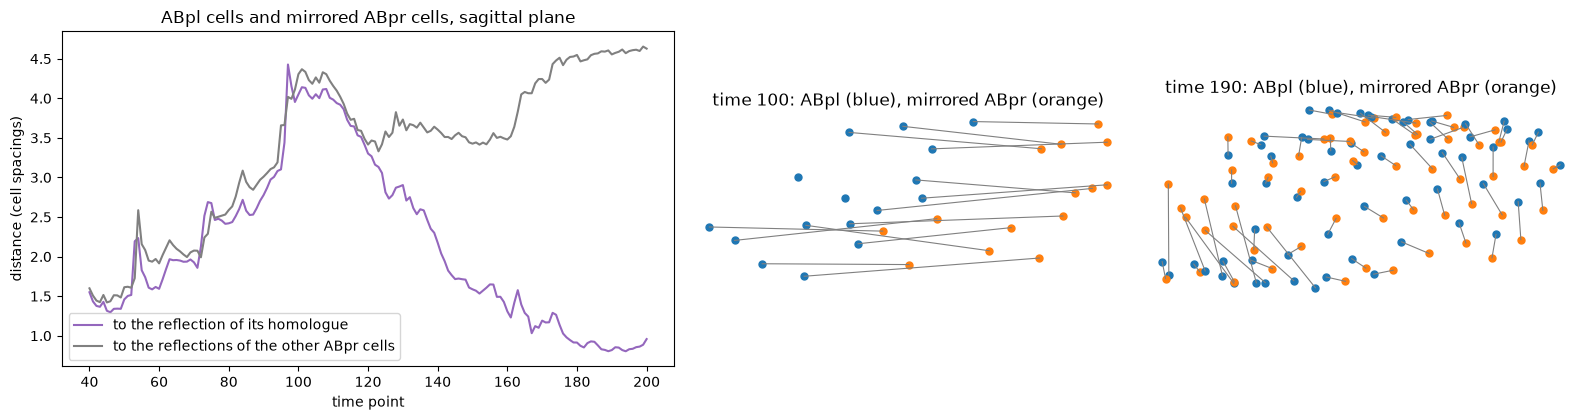

In [29]:
axes_at = {t: ct.body_axes(worm, t) for t in worm.time_nodes
           if any(worm.labels[n].startswith("ABpr") for n in worm.time_nodes[t])}

times = sorted(t for t in axes_at if t >= 40)
to_homologue, to_others = [], []
for t in times:
    left = {worm.labels[n]: np.asarray(worm.pos[n]) for n in worm.time_nodes[t] if worm.labels[n].startswith("ABpl")}
    right = {worm.labels[n]: ct.reflection(worm, n, axes_at) for n in worm.time_nodes[t]
             if worm.labels[n].startswith("ABpr")}
    same, other = [], []
    for name, p in left.items():
        for name_r, q in right.items():
            (same if name_r == ct.homologue(name) else other).append(np.linalg.norm(p - q) / spacing[t])
    to_homologue.append(np.median(same))
    to_others.append(np.median(other))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), width_ratios=(1.4, 1, 1))
axes[0].plot(times, to_homologue, color="tab:purple", label="to the reflection of its homologue")
axes[0].plot(times, to_others, color="grey", label="to the reflections of the other ABpr cells")
axes[0].set(xlabel="time point", ylabel="distance (cell spacings)",
            title="ABpl cells and mirrored ABpr cells, sagittal plane")
axes[0].legend()
for ax, t in zip(axes[1:], (100, 190), strict=True):
    for n in worm.time_nodes[t]:
        name = worm.labels[n]
        if name.startswith("ABpl"):
            partner = next((m for m in worm.time_nodes[t] if worm.labels[m] == ct.homologue(name)), None)
            on_left = ct.side_view(np.asarray(worm.pos[n]), axes_at[t])
            ax.scatter(*on_left, s=25, color="tab:blue")
            if partner is not None:
                on_right = ct.side_view(ct.reflection(worm, partner, axes_at), axes_at[t])
                ax.scatter(*on_right, s=25, color="tab:orange")
                ax.plot(*zip(on_left, on_right, strict=True), color="grey", lw=0.8)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"time {t}: ABpl (blue), mirrored ABpr (orange)")
fig.tight_layout()

print("shift of the mirrored ABpr cells from their ABpl homologues along the anterior-posterior axis")
print("(cell spacings, negative: posterior)")
for t in (60, 100, 140, 180, 200):
    centre, ap, lr, dv = axes_at[t]
    right = {worm.labels[n]: ct.reflection(worm, n, axes_at) for n in worm.time_nodes[t]
             if worm.labels[n].startswith("ABpr")}
    shift = [(right[ct.homologue(worm.labels[n])] - np.asarray(worm.pos[n])) @ ap / spacing[t]
             for n in worm.time_nodes[t]
             if worm.labels[n].startswith("ABpl") and ct.homologue(worm.labels[n]) in right]
    print(f"  time {t}: {np.mean(shift):+.1f}, posterior for {np.mean(np.array(shift) < 0):.0%} of the {len(shift)} pairs")

With this plane, the two sides look different until about time 120: every
mirrored ABpr cell sits posterior to its ABpl homologue, by up to 3.7 cell
spacings at time 100. But is the sagittal plane the right mirror? The
plane was forced to contain the long axis of the embryo. If the true plane
of symmetry is tilted, a perfectly symmetric embryo would show exactly this
kind of shift.

So instead, look for the best mirror plane at each time point: the plane
(any orientation, any position) whose reflection brings the ABpr cells
closest to their ABpl homologues, by least squares. For a given normal
vector the best position of the plane has a closed form, so only the
direction is optimised (`ct.best_mirror_plane`, with
`scipy.optimize.minimize` from several starting directions). The tilt of the plane is its angle with the long axis of the
embryo: 0° for a plane that contains it.

time 60: homologue at 0.7 cell spacings (sagittal plane: 1.6), other cells at 1.5; tilt 33°
time 100: homologue at 1.4 cell spacings (sagittal plane: 4.0), other cells at 2.5; tilt 47°
time 130: homologue at 1.0 cell spacings (sagittal plane: 2.9), other cells at 3.0; tilt 25°
time 150: homologue at 0.6 cell spacings (sagittal plane: 1.6), other cells at 3.3; tilt 10°
time 180: homologue at 0.7 cell spacings (sagittal plane: 0.9), other cells at 4.5; tilt 4°
time 200: homologue at 0.7 cell spacings (sagittal plane: 1.0), other cells at 4.6; tilt 3°


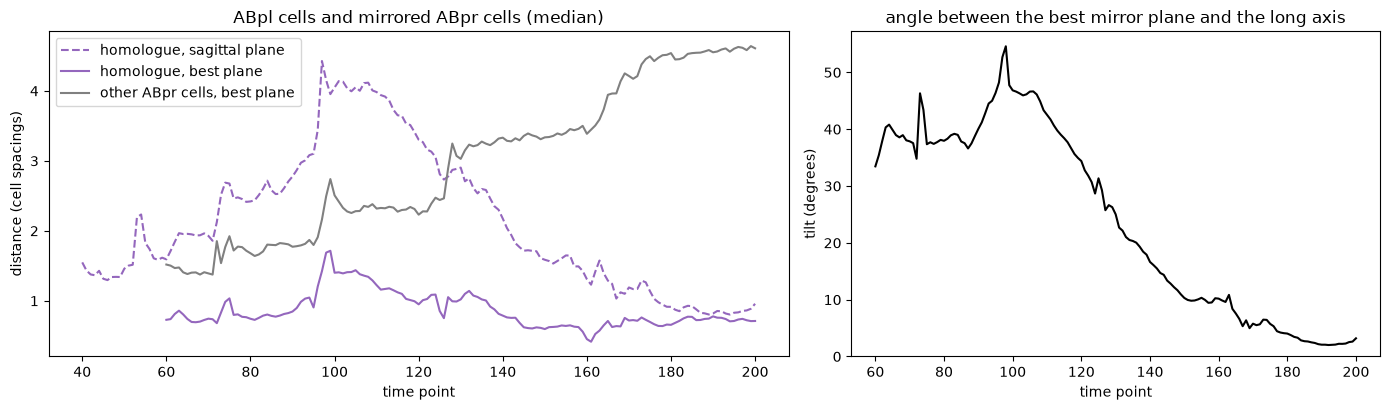

In [30]:
planes, best_homologue, best_others, tilt = {}, [], [], []
plane_times = [t for t in times if t >= 60]  # at least four pairs of cells to fit a plane
for t in plane_times:
    left = {worm.labels[n]: np.asarray(worm.pos[n]) for n in worm.time_nodes[t] if worm.labels[n].startswith("ABpl")}
    right = {worm.labels[n]: np.asarray(worm.pos[n]) for n in worm.time_nodes[t] if worm.labels[n].startswith("ABpr")}
    names_l = [name for name in left if ct.homologue(name) in right]
    L = np.array([left[name] for name in names_l])
    R = np.array([right[ct.homologue(name)] for name in names_l])
    centre, ap, lr, dv = axes_at[t]
    planes[t] = normal, offset = ct.best_mirror_plane(L, R, lr)
    mirrored = dict(zip(right, ct.mirror(np.array(list(right.values())), normal, offset), strict=True))
    best_homologue.append(np.median(np.linalg.norm(L - ct.mirror(R, normal, offset), axis=1)) / spacing[t])
    best_others.append(np.median([np.linalg.norm(left[a] - mirrored[b]) / spacing[t]
                                  for a in names_l for b in right if b != ct.homologue(a)]))
    tilt.append(90 - np.degrees(np.arccos(min(1, abs(normal @ ap)))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), width_ratios=(1.4, 1))
ax1.plot(times, to_homologue, color="tab:purple", ls="--", label="homologue, sagittal plane")
ax1.plot(plane_times, best_homologue, color="tab:purple", label="homologue, best plane")
ax1.plot(plane_times, best_others, color="grey", label="other ABpr cells, best plane")
ax1.set(xlabel="time point", ylabel="distance (cell spacings)",
        title="ABpl cells and mirrored ABpr cells (median)")
ax1.legend()
ax2.plot(plane_times, tilt, color="black")
ax2.set(xlabel="time point", ylabel="tilt (degrees)", ylim=(0, None),
        title="angle between the best mirror plane and the long axis")
fig.tight_layout()

for t in (60, 100, 130, 150, 180, 200):
    i = plane_times.index(t)
    print(f"time {t}: homologue at {best_homologue[i]:.1f} cell spacings (sagittal plane: "
          f"{to_homologue[times.index(t)]:.1f}), other cells at {best_others[i]:.1f}; tilt {tilt[i]:.0f}°")

The plane was the problem. With the best plane, each ABpl cell is about one
cell spacing from the reflection of its homologue, and closer to it than to
the other mirrored cells, from time 60 on: the two sides are mirror images
much earlier than the sagittal plane suggested. But the mirror is tilted:
its angle with the long axis of the embryo is about 40° (up to 55°) until
time 110, then it turns to contain the long axis from about time 150 on. The
"posterior shift" of the right cells was this tilt.

This is the tilted midline described by
[Pohl & Bao (2010)](https://doi.org/10.1016/j.devcel.2010.08.014): the
8-cell embryo sets a midline tilted from the anterior–posterior axis, which
places more cells on the left, before the two axes are brought back
together.

In [31]:
# whole trajectories: the ABpr lineage mirrored, in a new tree with the same nodes
mirrored = LineageTree(
    successor={n: list(s) for n, s in worm.successor.items()},
    pos={n: ct.mirrored_position(worm, n, planes, axes_at) if worm.labels[n].startswith("ABpr") else worm.pos[n]
         for n in worm.nodes},
    name="ABpr mirrored",
)
lefts = sorted(name for name in cell if name.startswith("ABpl") and ct.generation(name) == 7)
rights = [ct.homologue(name) for name in lefts]
same, other = [], []
for name in lefts:
    distance = {r: mirrored.dtw(cell[name], cell[r], regist=False)[0] for r in rights}
    same.append(distance[ct.homologue(name)])
    other.append(np.median([d for r, d in distance.items() if r != ct.homologue(name)]))
same, other = np.array(same), np.array(other)
print(f"{len(lefts)} ABpl cells of generation 7, DTW distance to the mirrored ABpr cells:")
print(f"  to their homologue: median {np.median(same):.1f}; to the others: median {np.median(other):.1f}")
print(f"  the homologue is the closest in {np.mean(same < other):.0%} of the cells")

32 ABpl cells of generation 7, DTW distance to the mirrored ABpr cells:
  to their homologue: median 14.0; to the others: median 67.4
  the homologue is the closest in 100% of the cells


The trajectories agree. `dtw`, run on a copy of the tree in which the ABpr
cells are reflected through the best plane of each time point, finds that
the trajectory of each ABpl cell of generation 7 is closer to the mirrored
trajectory of its homologue than to those of all the other cells. Case
study 19 shows that the homologous lineages are also alike in what they
make.

## 18. A fate map from tissue reporters

Each of the 104 conditions of section 5 is one knockdown, but most
knockdowns leave most cells unchanged. Taking, for each cell, the median
over the conditions of a reporter gives a good picture of where the
reporter is expressed in a normal embryo, and so of the fate of each cell:
pharynx (or gut, for *pha-4*), hypodermis (*nhr-25*) or neurons (*cnd-1*).

Two precautions. The knockdown embryos were followed for a shorter time
than this one, so the conditions cover fewer and fewer cells after time
155: the map is built on the time points 140 to 155. And each condition has
its own scale, so its values are z-scored over these time points first.
The score of a cell for a tissue is the median, over the conditions of that
tissue, of its mean z-score; its fate is the tissue with the highest score,
if that score is above 0.5, and "none" otherwise.

fraction of the cells of a time point that a condition covers (median over the conditions):
  time 100: 100% of 85 cells
  time 150:  94% of 188 cells
  time 155:  90% of 194 cells
  time 160:  78% of 208 cells
  time 170:  34% of 295 cells
  time 200:  15% of 360 cells


fates of the 194 cells: {'none': 120, 'HYP': 28, 'PHA': 26, 'NEU': 20}


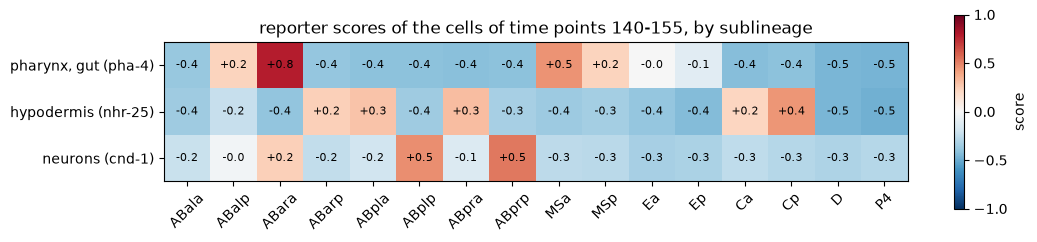

In [32]:
TISSUES = ct.TISSUES  # the three reporters, and their colours
SUBLINEAGES = ct.SUBLINEAGES
values_of = {c: getattr(worm, c) for c in conditions}

print("fraction of the cells of a time point that a condition covers (median over the conditions):")
for t in (100, 150, 155, 160, 170, 200):
    coverage = [np.mean([not np.isnan(values.get(n, np.nan)) for n in worm.time_nodes[t]])
                for values in values_of.values()]
    print(f"  time {t}: {np.median(coverage):4.0%} of {len(worm.time_nodes[t])} cells")

T_FATE = (140, 155)
window = [n for n in worm.nodes if T_FATE[0] <= worm.time[n] <= T_FATE[1]]
zscored = {c: ct.zscore(values_of[c], window) for c in conditions}  # z-scored over the window
of_tissue = defaultdict(list)
for c in conditions:
    of_tissue[worm.gene_dict[c].rsplit("_", 1)[1]].append(c)

# the cells alive at the end of the window: their scores, and their fates
fate_cells = sorted({worm.get_chain_of_node(n)[0] for n in worm.time_nodes[T_FATE[1]]})
score = {}
for first in fate_cells:
    in_window = [n for n in chain_of[first] if T_FATE[0] <= worm.time[n] <= T_FATE[1]]
    for tissue, conds in of_tissue.items():
        score[first, tissue] = ct.median_score(zscored, in_window, conds)
fate = {first: ct.call_fate({t: score[first, t] for t in TISSUES}) for first in fate_cells}

heat = np.array([[np.nanmean([score[c, t] for c in fate_cells if ct.sublineage(worm.labels[c]) == s])
                  for s in SUBLINEAGES] for t in TISSUES])
fig, ax = plt.subplots(figsize=(12, 2.8))
im = ax.imshow(heat, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(SUBLINEAGES)), SUBLINEAGES, rotation=45)
ax.set_yticks(range(len(TISSUES)), ["pharynx, gut (pha-4)", "hypodermis (nhr-25)", "neurons (cnd-1)"])
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        ax.text(j, i, f"{heat[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="score", shrink=0.9)
ax.set_title(f"reporter scores of the cells of time points {T_FATE[0]}-{T_FATE[1]}, by sublineage")

print(f"fates of the {len(fate_cells)} cells:", dict(Counter(fate.values())))

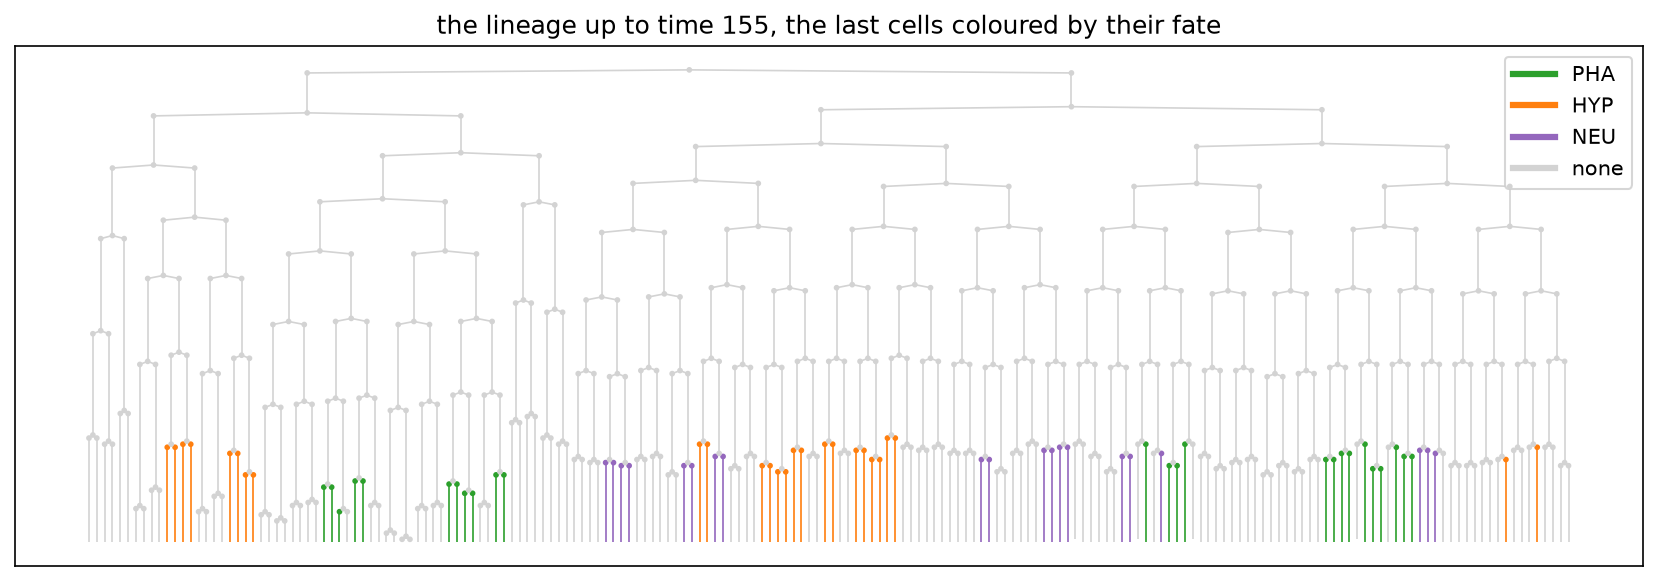

In [33]:
FATE_COLOURS = {**TISSUES, "none": "lightgrey"}
colours = {}
for first in fate_cells:
    colours[first] = colours[chain_of[first][-1]] = FATE_COLOURS[fate[first]]
fig, ax = worm.plot_subtree(cell["P0"], end_time=T_FATE[1], figsize=(14, 4.5), size=3, lw=0.8,
                            color_of_nodes=colours, color_of_edges=colours, default_color="lightgrey")
ax.legend(handles=[plt.Line2D([], [], color=c, lw=3, label=f) for f, c in FATE_COLOURS.items()],
          loc="upper right")
ax.set_title(f"the lineage up to time {T_FATE[1]}, the last cells coloured by their fate");

In [34]:
nodes = sorted(worm.time_nodes[T_FATE[1]])
node_fate = {n: fate[worm.get_chain_of_node(n)[0]] for n in nodes}
traces = []
for f, colour in FATE_COLOURS.items():
    members = [n for n in nodes if node_fate[n] == f]
    xyz = np.array([worm.pos[n] for n in members])
    traces.append(go.Scatter3d(x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2], mode="markers", name=f,
                               marker=dict(size=7, color=colour.replace("tab:", "")),
                               text=[worm.labels[n] for n in members], hoverinfo="text"))
fig = go.Figure(traces)
fig.update_layout(title=f"time {T_FATE[1]}: cells coloured by fate", scene=dict(aspectmode="data"), height=600)
fig.show()

# where are the cells of each fate? depth (case study 16) and position along the body
centre, ap, lr, dv = ct.body_axes(worm, T_FATE[1])
along = {n: (np.asarray(worm.pos[n]) - centre) @ ap for n in nodes}
low, high = min(along.values()), max(along.values())
for f in FATE_COLOURS:
    members = [n for n in nodes if node_fate[n] == f]
    d = np.array([depth[n] for n in members])
    position = np.mean([(along[n] - low) / (high - low) for n in members])
    print(f"{f:5} {len(members):4} cells: median depth {np.median(d):4.2f}, at the surface {np.mean(d < 0.5):4.0%}, "
          f"mean position along the body {position:.2f} (0 posterior, 1 anterior)")

# are neighbours of the same fate? Gabriel edges between cells with a fate, against shuffled fates
called = [n for n in nodes if node_fate[n] != "none"]
edges = {tuple(sorted((a, b))) for a in called for b in gabriel.get(a, ()) if b in called}
rng = np.random.default_rng(0)
shuffled = [ct.same_fate_fraction(dict(zip(called, rng.permutation([node_fate[n] for n in called]), strict=True)),
                                 edges) for _ in range(200)]
print(f"neighbours with the same fate: {ct.same_fate_fraction(node_fate, edges):.0%} of {len(edges)} pairs "
      f"(shuffled fates: {np.mean(shuffled):.0%} ± {np.std(shuffled):.0%})")

PHA     26 cells: median depth 0.87, at the surface  42%, mean position along the body 0.77 (0 posterior, 1 anterior)
HYP     28 cells: median depth -0.00, at the surface  96%, mean position along the body 0.27 (0 posterior, 1 anterior)
NEU     20 cells: median depth 0.00, at the surface 100%, mean position along the body 0.58 (0 posterior, 1 anterior)
none   120 cells: median depth 0.21, at the surface  68%, mean position along the body 0.55 (0 posterior, 1 anterior)
neighbours with the same fate: 75% of 164 pairs (shuffled fates: 33% ± 3%)


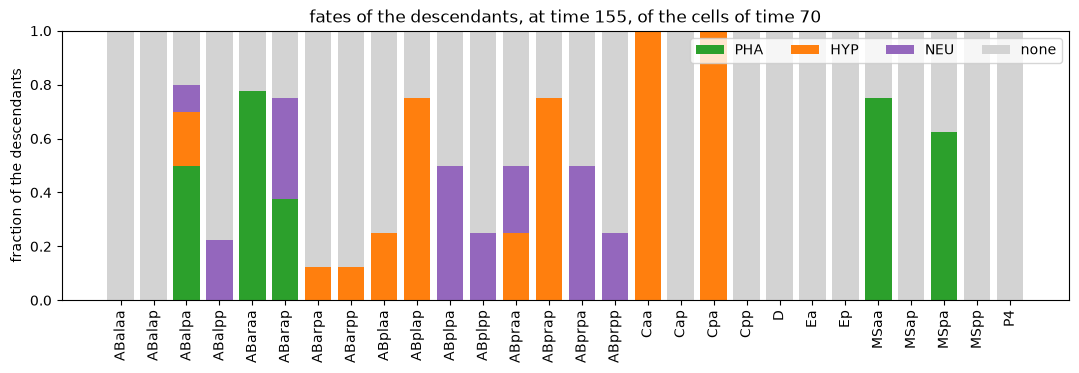

In [35]:
# what will the cells of the 28-cell stage (time T28 of section 8) make?
cells_28 = sorted(worm.time_nodes[T28], key=lambda n: worm.labels[n])
shares = np.array([[np.mean([fate[worm.get_chain_of_node(d)[0]] == f for d in worm.nodes_at_t(T_FATE[1], n)])
                    for f in FATE_COLOURS] for n in cells_28])
fig, ax = plt.subplots(figsize=(13, 3.5))
bottom = np.zeros(len(cells_28))
for k, (f, colour) in enumerate(FATE_COLOURS.items()):
    ax.bar([worm.labels[n] for n in cells_28], shares[:, k], bottom=bottom, color=colour, label=f)
    bottom += shares[:, k]
ax.set(ylabel="fraction of the descendants",
       title=f"fates of the descendants, at time {T_FATE[1]}, of the cells of time {T28}")
ax.tick_params(axis="x", rotation=90)
ax.legend(ncol=4, loc="upper right");

The map is the one of the textbook. The pharynx reporter is on in ABara,
MSa, ABalp and MSp, the four sublineages that make the pharynx, two of
which, ABalp and ABara, are induced by MS (case study 15). The hypodermis
reporter is on in Cp, ABpra, ABpla, ABarp and Ca, and the neuronal reporter
in ABprp and ABplp, two sublineages rich in neurons. The gut (E) is not
called yet: *pha-4* comes on later there.

In space, nearly all the hypodermal cells are at the surface, in the
posterior half of the embryo; the pharyngeal cells are deeper and anterior,
where the pharynx forms. Cells of the same fate are neighbours: three
quarters of the contacts between cells with a fate join two cells of the
same fate, twice as many as with shuffled fates.

Fates are sorted early. At the 28-cell stage, the anterior daughters of C,
Caa and Cpa, make hypodermis, while their posterior sisters Cap and Cpp
make none of the three tissues (they make body muscle, which no reporter
marks here). In MS, the anterior daughters MSaa and MSpa make pharynx and
their posterior sisters again none. Each of these a/p divisions separates
two fates, as in case study 13.

## 19. Lineages compared by their timing and their fate

The unordered tree edit distance of section 8 compares the timing of two
lineages: in the `simple` style, each cell is a node weighted by its
lifetime, matching two cells costs the difference of their lifetimes, and
adding or removing a cell costs its lifetime. Fates can be added to it. A
style is a class, and subclassing `simple_tree` to redefine `delta`, the
cost of an edit, gives a distance that also counts how differently two
matched cells express the reporters: `ct.SimpleWithReporters`, in
`celegans_tools.py`.

Here each node of the embryo carries its three reporter scores (pharynx,
hypodermis, neurons): for each reporter, the median of its conditions,
z-scored up to time 155 as in case study 18. A cell carries the mean of
its nodes. Matching two cells adds the difference of their scores times
their common lifetime; adding or removing a cell adds its scores times its
lifetime. With `weight = 1`, a difference of one standard deviation over
the whole life of a cell costs as much as one whole cell cycle of timing.

In [36]:
# the three reporter scores of each node up to time 155: median over the conditions of a reporter
early = [n for n in worm.nodes if worm.time[n] <= T_FATE[1]]
z_early = {}
for c in conditions:
    x = np.array([values_of[c].get(n, np.nan) for n in early])
    z_early[c] = (x - np.nanmean(x)) / np.nanstd(x)
with warnings.catch_warnings():  # nodes that no condition of a reporter measured
    warnings.simplefilter("ignore", RuntimeWarning)
    channels = np.array([np.nanmedian([z_early[c] for c in of_tissue[t]], axis=0) for t in TISSUES])
worm.reporters = {n: channels[:, i] for i, n in enumerate(early) if np.isfinite(channels[:, i]).all()}
print(f"{len(worm.reporters)} nodes with the three reporter scores, e.g. MSaa at time 150:",
      next(worm.reporters[n].round(1) for n in worm.time_nodes[150] if worm.labels[n].startswith("MSaa")))

9999 nodes with the three reporter scores, e.g. MSaa at time 150: [ 3.6 -0.2 -0.1]


### Where do sisters part ways?

In the ascidian embryo, [Guignard et al. (2020)](https://doi.org/10.1126/science.aar5663)
compared the descendants of sister cells to find the asymmetric divisions,
and linked them to differential inductions of the two sisters. The same
can be done here: for each division, the distance between the lineages of
the two daughters over the 60 time points that follow their birth, with
the timing alone (`simple`) and with the reporters. Only the divisions
early enough for this window to end by time 155 are scored.

most divergent sisters, timing: P3 0.86, P2 0.72, EMS 0.68, P0 0.56, P1 0.34, Cp 0.33, ABprap 0.24, Caa 0.23
most divergent sisters, timing and reporters: ABarap 0.64, ABplaap 0.62, EMS 0.54, P2 0.50, P0 0.48, ABprpa 0.47, P3 0.46, ABplpa 0.46


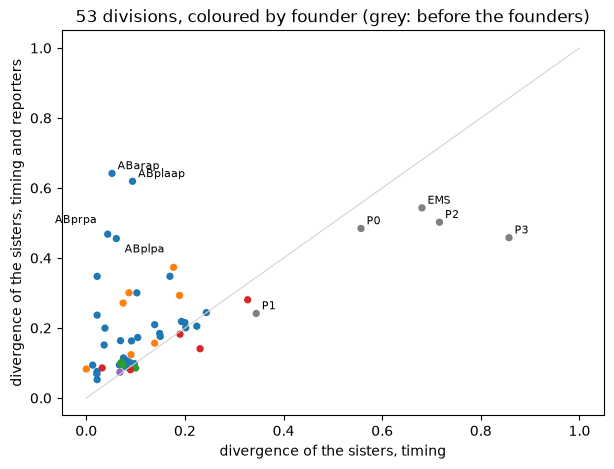

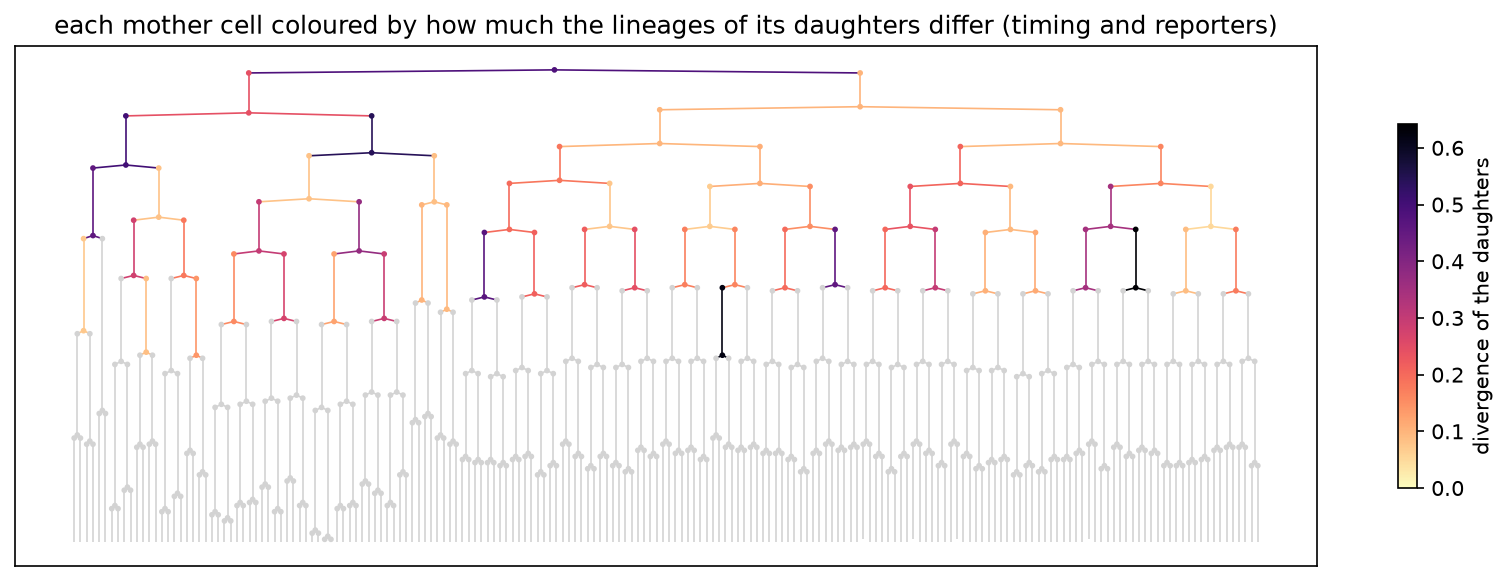

In [37]:
WINDOW = 60  # time points after the birth of the daughters
timing_only = ct.sister_divergence(worm, "simple", WINDOW, T_FATE[1])
with_fate = ct.sister_divergence(worm, ct.SimpleWithReporters, WINDOW, T_FATE[1])
for label, values in (("timing", timing_only), ("timing and reporters", with_fate)):
    top = sorted(values, key=values.get, reverse=True)[:8]
    print(f"most divergent sisters, {label}:", ", ".join(f"{worm.labels[m]} {values[m]:.2f}" for m in top))

fig, ax = plt.subplots(figsize=(7, 5))
mothers = list(timing_only)
ax.scatter([timing_only[m] for m in mothers], [with_fate[m] for m in mothers], s=18,
           color=[FOUNDERS.get(ct.founder_of(worm, m), "grey") for m in mothers])
OFFSETS = {"ABprpa": (-38, 8), "ABplpa": (6, -10)}  # labels that would overlap
for m in set(sorted(mothers, key=timing_only.get)[-5:] + sorted(mothers, key=with_fate.get)[-8:]):
    ax.annotate(worm.labels[m], (timing_only[m], with_fate[m]), xytext=OFFSETS.get(worm.labels[m], (4, 3)),
                textcoords="offset points", fontsize=8)
ax.plot([0, 1], [0, 1], color="lightgrey", lw=0.8)
ax.set(xlabel="divergence of the sisters, timing", ylabel="divergence of the sisters, timing and reporters",
       title=f"{len(mothers)} divisions, coloured by founder (grey: before the founders)")

# the divergence with reporters, on the lineage
cmap = plt.get_cmap("magma_r")
top_value = max(with_fate.values())
colours = {}
for m, value in with_fate.items():
    colours[m] = colours[chain_of[m][-1]] = cmap(value / top_value)
fig, ax = worm.plot_subtree(cell["P0"], end_time=T_FATE[1], figsize=(14, 4.5), size=3, lw=0.8,
                            color_of_nodes=colours, color_of_edges=colours, default_color="lightgrey")
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, top_value)), ax=ax, shrink=0.7,
             label="divergence of the daughters")
ax.set_title("each mother cell coloured by how much the lineages of its daughters differ (timing and reporters)");

Timing alone ranks first the divisions of the germline: P3 (into D and
P4), P2 (C and P3), EMS (MS and E), P0 (AB and P1) and P1 (EMS and P2),
which make founder lineages with different clocks (case study 11). With
the reporters, divisions of AB come forward, whose daughters divide alike
but make different tissues:

- ABarap: pharynx in ABarapa, neurons in ABarapp;
- ABplaap: hypodermis in ABplaapp, none of the three tissues in ABplaapa;
- ABplpa and ABprpa, a left/right pair: neurons in the anterior daughter,
  none of the three tissues in the posterior one.

MSa and MSp follow: pharynx in MSaa and MSpa, none of the three tissues
(they make muscle) in MSap and MSpp. The reporters turn a timing distance
into a map of the divisions that separate tissues.

### Are the left and right lineages alike?

Case study 17 showed that the ABpl and ABpr cells end up at mirror
positions. Are their lineages alike too? For each ABpl lineage, the
distance to every ABpr lineage of the same generation, up to time 155:
is its homologue the closest one?

generation 4, timing: rank of the homologue [1, 2, 2, 2]
generation 5, timing: rank of the homologue [6, 1, 2, 8, 5, 4, 3, 2]


generation 6, timing: rank of the homologue [14, 4, 5, 1, 4, 2, 13, 14, 11, 9, 8, 5, 3, 8, 6, 3]


generation 4, timing and reporters: rank of the homologue [1, 1, 1, 1]
generation 5, timing and reporters: rank of the homologue [4, 1, 1, 1, 1, 2, 1, 1]


generation 6, timing and reporters: rank of the homologue [6, 5, 1, 1, 1, 2, 3, 3, 1, 1, 3, 5, 1, 1, 1, 1]


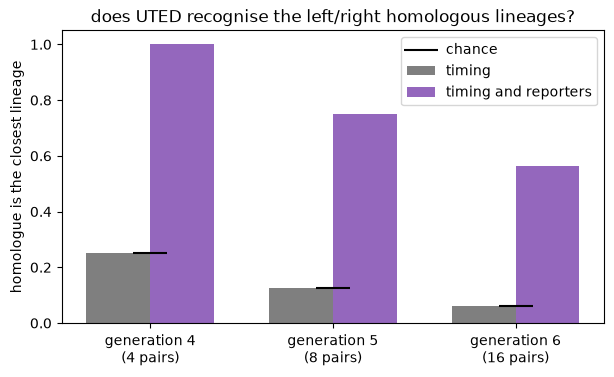

In [38]:
fig, ax = plt.subplots(figsize=(7, 3.8))
gens = [4, 5, 6]
for k, (label, style, colour) in enumerate((("timing", "simple", "tab:grey"),
                                             ("timing and reporters", ct.SimpleWithReporters, "tab:purple"))):
    closest = []
    for gen in gens:
        ranks = ct.homologue_rank(worm, cell, gen, style, T_FATE[1])
        closest.append(np.mean(np.array(ranks) == 1))
        print(f"generation {gen}, {label}: rank of the homologue {ranks}")
    ax.bar(np.arange(len(gens)) + 0.35 * (k - 0.5), closest, width=0.35, color=colour, label=label)
chance = [1 / 2 ** (gen - 2) for gen in gens]
ax.scatter(range(len(gens)), chance, marker="_", s=600, color="black", label="chance", zorder=3)
ax.set_xticks(range(len(gens)), [f"generation {g}\n({2 ** (g - 2)} pairs)" for g in gens])
ax.set(ylabel="homologue is the closest lineage", ylim=(0, 1.05),
       title="does UTED recognise the left/right homologous lineages?")
ax.legend();

Timing alone does not recognise the homologues: the homologous lineage is
the closest one no more often than by chance, since the two sides do not
divide at exactly the same times (ABpl is ahead, case study 12). With the
reporters, it is the closest in all 4 cases at generation 4, in 6 of 8 at
generation 5 and in 9 of 16 at generation 6 (chance: 1 in 4, 8 and 16).
The left and right lineages make the same tissues.

## 20. Relatives stay together and share their fate

How far apart are two cells, given how closely related they are? The
lineage distance between two cells is the number of divisions back to their
last common ancestor: 1 for sisters, 2 for cousins, and so on. Below, the
distance in space between every pair of cells at the end of the recording,
and the fraction of the pairs of cells with a fate (case study 18) that
have the same one.

lineage distance:         1     2     3     4     5     6     7     8
distance in space:      1.2   1.9   2.3   3.3   4.2   5.2   6.6   7.1
same fate:             1.00  0.86  0.77  0.62  0.25  0.49  0.16  0.31   (all pairs 0.33)
sisters in contact (Gabriel neighbours): 93% of 174 pairs


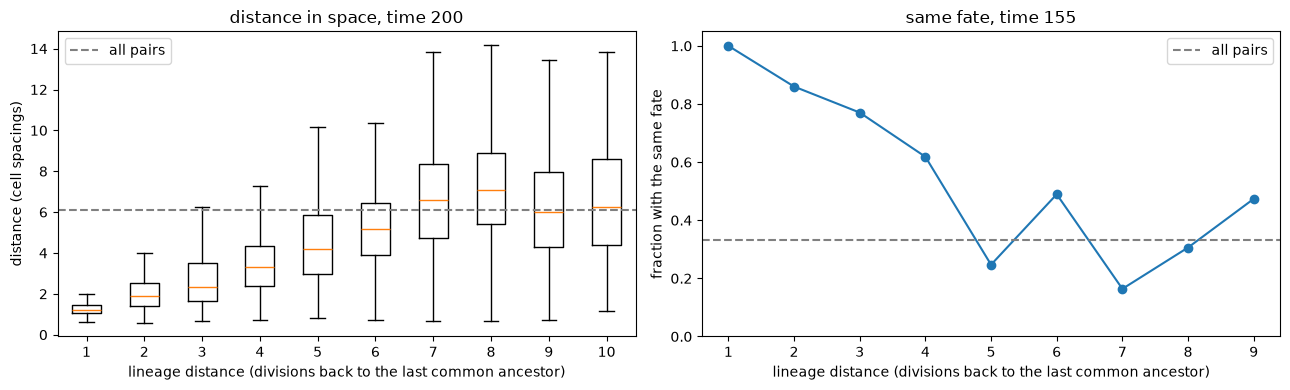

In [39]:
end_nodes = sorted(worm.time_nodes[worm.t_e])
ancestry_of = {n: ct.ancestry(worm, n) for n in end_nodes + fate_cells}  # cells from the root
unit = spacing[worm.t_e]
in_space = defaultdict(list)  # lineage distance -> distances, in cell spacings
for a, b in itertools.combinations(end_nodes, 2):
    d = np.linalg.norm(np.asarray(worm.pos[a]) - np.asarray(worm.pos[b])) / unit
    in_space[ct.lineage_distance(ancestry_of[a], ancestry_of[b])].append(d)
with_fate = [c for c in fate_cells if fate[c] != "none"]
same = defaultdict(list)  # lineage distance -> same fate or not
for a, b in itertools.combinations(with_fate, 2):
    same[ct.lineage_distance(ancestry_of[a], ancestry_of[b])].append(fate[a] == fate[b])
chance = np.mean([fate[a] == fate[b] for a, b in itertools.combinations(with_fate, 2)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ks = sorted(k for k in in_space if len(in_space[k]) >= 10)
ax1.boxplot([in_space[k] for k in ks], positions=ks, showfliers=False)
ax1.axhline(np.median([d for v in in_space.values() for d in v]), color="grey", ls="--", label="all pairs")
ax1.set(xlabel="lineage distance (divisions back to the last common ancestor)",
        ylabel="distance (cell spacings)", title=f"distance in space, time {worm.t_e}")
ax1.legend()
ks = sorted(k for k in same if len(same[k]) >= 10)
ax2.plot(ks, [np.mean(same[k]) for k in ks], "o-")
ax2.axhline(chance, color="grey", ls="--", label="all pairs")
ax2.set(xlabel="lineage distance (divisions back to the last common ancestor)", ylim=(0, 1.05),
        ylabel="fraction with the same fate", title=f"same fate, time {T_FATE[1]}")
ax2.legend()
fig.tight_layout()

print("lineage distance:     " + " ".join(f"{k:5}" for k in range(1, 9)))
print("distance in space:    " + " ".join(f"{np.median(in_space[k]):5.1f}" for k in range(1, 9)))
print("same fate:            " + " ".join(f"{np.mean(same[k]):5.2f}" for k in range(1, 9)) + f"   (all pairs {chance:.2f})")
sisters = [(a, b) for a, b in itertools.combinations(end_nodes, 2) if ct.lineage_distance(ancestry_of[a], ancestry_of[b]) == 1]
print(f"sisters in contact (Gabriel neighbours): {np.mean([b in gabriel.get(a, ()) for a, b in sisters]):.0%} of {len(sisters)} pairs")

Relatives stay together: sisters are about one cell spacing apart and in
contact in 9 cases out of 10, and the distance grows steadily with the
lineage distance, up to seven spacings for cells whose last common
ancestor lived eight divisions earlier. The lineage is laid out in space as
coherent patches of related cells.

They also share their fate: nearly all sisters and cousins have the same
one, and the fraction drops to the level of random pairs beyond four
divisions. Part of this is trivial, since a reporter protein made in a
mother is inherited by its daughters; but it echoes the finding of
[Du et al. (2015)](https://doi.org/10.1016/j.devcel.2015.07.014), from the
same knockdowns, that the barriers between fates grow with lineage
distance.

## 21. Knockdowns that redraw the fate map

How is a change measured? For one reporter, say the pharynx reporter, and
one knockdown:

1. the values of the knockdown are z-scored over the time points 140 to
   155 (case study 18), so that all the conditions are on the same scale;
2. its **profile** is the mean z-score of each sublineage (ABala, ABalp, …,
   D) over these time points;
3. the **typical profile** is, for each sublineage, the median of the
   profiles of the 33 knockdowns recorded with this reporter: since most
   knockdowns leave a given sublineage alone, it stands for the normal
   expression;
4. the **change** of the knockdown in a sublineage is its profile minus the
   typical profile: positive if the sublineage expresses the reporter more
   than usual, negative if less.

Below, the changes of the 33 knockdowns, ordered so that knockdowns with
similar changes are next to each other. Hover over the map for the values.

In [40]:
SUBLINEAGES_KD = SUBLINEAGES[:-1]  # P4 is too small to be measured reliably
sublineage_of = {n: ct.sublineage(worm.labels[n]) for n in window}

# the profile of each knockdown of the pharynx reporter, and its change against the median profile
conds = sorted(of_tissue["PHA"], key=lambda c: worm.gene_dict[c])
profiles = np.array([ct.sublineage_profile(zscored[c], sublineage_of, SUBLINEAGES_KD) for c in conds])
delta = profiles - np.nanmedian(profiles, axis=0)

similarity = np.ma.corrcoef(np.ma.masked_invalid(delta)).filled(0)
order = leaves_list(linkage(squareform(1 - similarity, checks=False), method="average"))
names = [worm.gene_dict[conds[i]].replace("_PHA", "") for i in order]
fig = go.Figure(go.Heatmap(z=delta[order], x=SUBLINEAGES_KD, y=names, colorscale="RdBu_r", zmid=0,
                           zmin=-2, zmax=2, colorbar=dict(title="change"),
                           hovertemplate="%{y} in %{x}: %{z:+.2f}<extra></extra>"))
fig.update_layout(title="pharynx reporter: change in each sublineage, against the median of the knockdowns",
                  height=750, width=800, yaxis=dict(autorange="reversed"))
fig.show()

genes_pha = [worm.gene_dict[c].replace("_PHA", "") for c in conds]
for gene in ("GSK-3", "CUL-1", "SKR-2", "LIN-23", "ELT-1", "SPN-4"):
    ct.report_change(gene, delta[genes_pha.index(gene)], SUBLINEAGES_KD)
i, j = (names.index(g) for g in ("SKR-2", "LIN-23"))
print(f"correlation of the changes, SKR-2 and LIN-23: {similarity[order[i], order[j]]:.2f}")

GSK-3   lost in ABara -1.5, MSa -0.7     gained in ABala +2.0, Cp +1.6, Ca +1.0
CUL-1   lost in ABara -1.4               gained in Cp +1.2, ABalp +0.8
SKR-2   lost in ABara -1.4               gained in ABarp +1.5
LIN-23  lost in ABara -1.6               gained in ABarp +1.6
ELT-1   lost in -                        gained in Ea +2.6, Ep +1.9
SPN-4   lost in ABalp -0.8, MSa -0.6     gained in Ea +2.4, Ep +1.4
correlation of the changes, SKR-2 and LIN-23: 0.99


Some knockdowns redraw the map in ways that match what is known of the
genes:

- **GSK-3**: the pharynx reporter appears in the C lineage (and in ABala)
  and is lost from ABara. GSK-3 represses the mesendoderm genes in the C
  lineage ([Maduro et al. 2001](https://doi.org/10.1016/s1097-2765(01)00195-2)):
  without it, C behaves like EMS, the mother of the pharynx and gut
  precursors MS and E.
- **CUL-1, SKR-2 and LIN-23**: the three knockdowns lose the reporter in
  ABara, and in two of them its sister ABarp gains it. The three genes code
  for parts of one kind of ubiquitin ligase, an SCF complex: a cullin, a
  Skp1 and an F-box protein. The changes of SKR-2 and LIN-23 are the most
  similar of all the pairs of knockdowns: genes that work together have
  the same phenotype.
- **ELT-1, SPN-4** and a few others: the reporter appears early in E, the
  gut precursors, where *pha-4* is expressed later in development.

This is the logic of a screen: the lineage gives every cell an identity,
so a phenotype can be read cell by cell and compared between genes.

### The same comparison with the tree edit distance

The changes above match the cells by their names: ABara of the knockdown
against ABara of the typical profile. UTED does without names: it first
aligns the two lineages, then sums the cost of the differences. Here the
style of case study 19, with the pharynx reporter only, compares each
knockdown with the typical profile (the median of the 33 knockdowns, node
by node), on each founder lineage. Both are annotated on the lineage of
this embryo, so the trees have the same shape and only the reporter
differs. `LineageTreeManager` compares lineages of different trees, so each
annotation becomes its own tree.

For comparison, the same costs with the cells matched by name: the
**cell-by-cell** distance. Since this matching is one of those UTED
considers, UTED can only be lower; it is lower when another matching of
the cells costs less.

ABa lineage, UTED / cell-by-cell distance, lowest: LIN-23 0.43, SKR-2 0.45, GSK-3 0.66, CUL-1 0.74 (median over the knockdowns 0.96)


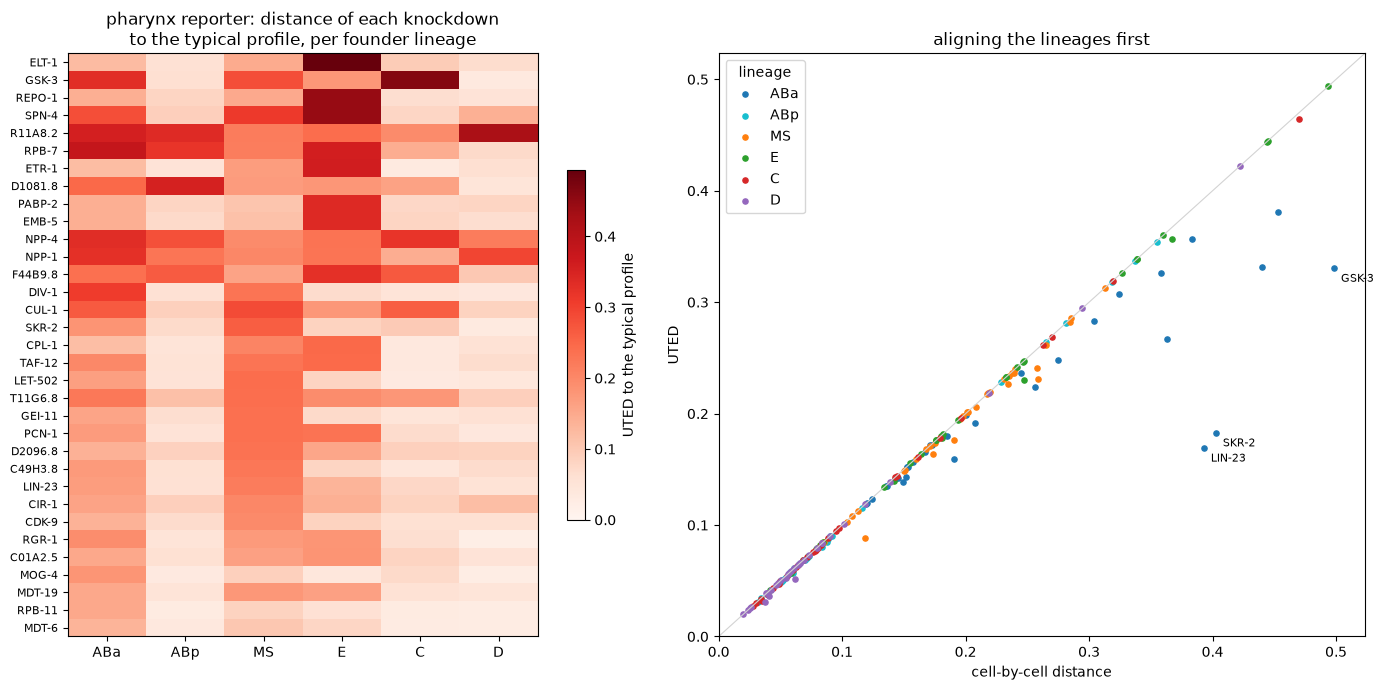

In [41]:
LINEAGES_KD = ["ABa", "ABp", "MS", "E", "C", "D"]
pha = of_tissue["PHA"]
z_pha = np.array([z_early[c] for c in pha])
with warnings.catch_warnings():  # nodes that no knockdown measured
    warnings.simplefilter("ignore", RuntimeWarning)
    typical_pha = np.nanmedian(z_pha, axis=0)

comparison = LineageTreeManager()
comparison.add(ct.annotated_copy(worm, early, typical_pha, "typical"), "typical")
uted_change, named_change = {}, {}
for c, values in zip(pha, z_pha, strict=True):
    gene = worm.gene_dict[c].replace("_PHA", "")
    comparison.add(ct.annotated_copy(worm, early, values, gene), gene)
    for lineage in LINEAGES_KD:
        r = cell[lineage]
        uted_change[gene, lineage] = float(comparison.cross_lineage_edit_distance(
            r, "typical", r, gene, T_FATE[1], T_FATE[1], style=ct.SimpleWithReporters))
        named_change[gene, lineage] = ct.cell_by_cell_distance(worm, early, typical_pha, values, r, T_FATE[1])
    comparison.remove_embryo(gene)
    comparison.clear_comparisons()

genes = sorted({g for g, _ in uted_change}, key=lambda g: -max(uted_change[g, lin] for lin in LINEAGES_KD))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), width_ratios=(1, 1.1))
table = np.array([[uted_change[g, lin] for lin in LINEAGES_KD] for g in genes])
im = ax1.imshow(table, cmap="Reds", vmin=0, aspect="auto")
ax1.set_xticks(range(len(LINEAGES_KD)), LINEAGES_KD)
ax1.set_yticks(range(len(genes)), genes, fontsize=8)
fig.colorbar(im, ax=ax1, label="UTED to the typical profile", shrink=0.6)
ax1.set_title("pharynx reporter: distance of each knockdown\nto the typical profile, per founder lineage")
for lineage, colour in zip(LINEAGES_KD, ("tab:blue", "tab:cyan", "tab:orange", "tab:green", "tab:red", "tab:purple"),
                           strict=True):
    ax2.scatter([named_change[g, lineage] for g in genes], [uted_change[g, lineage] for g in genes],
                s=14, color=colour, label=lineage)
for g in ("LIN-23", "SKR-2", "GSK-3"):
    ax2.annotate(g, (named_change[g, "ABa"], uted_change[g, "ABa"]), xytext=(5, -10), textcoords="offset points",
                 fontsize=8)
top = max(named_change.values()) * 1.05
ax2.plot([0, top], [0, top], color="lightgrey", lw=0.8)
ax2.set(xlabel="cell-by-cell distance", ylabel="UTED", title="aligning the lineages first",
        xlim=(0, top), ylim=(0, top))
ax2.legend(title="lineage")
fig.tight_layout()

ratio = {g: uted_change[g, "ABa"] / named_change[g, "ABa"] for g in genes}
print("ABa lineage, UTED / cell-by-cell distance, lowest:", ", ".join(f"{g} {ratio[g]:.2f}" for g in sorted(ratio, key=ratio.get)[:4]),
      f"(median over the knockdowns {np.median(list(ratio.values())):.2f})")

UTED finds the same knockdowns as the profiles: the E lineage for ELT-1,
SPN-4, REPO-1 and the others whose gut expresses the reporter early, the C
and ABa lineages for GSK-3. For most knockdowns and lineages, the two
distances are equal: aligning the lineages changes nothing.

The ABa lineage is the exception, and the most striking cases are LIN-23
and SKR-2, where UTED is less than half the cell-by-cell distance. These
knockdowns swap the fates of two sisters: ABara loses the pharynx reporter
and ABarp gains it. UTED does not care about the order of sisters, so it
aligns the ABarp of the knockdown with the ABara of the typical profile,
and the swap costs almost nothing; for GSK-3, the gain in ABala and the
loss in ABara are partly matched by aligning ABal with ABar. This is a
strength when cell names are missing or unreliable, as in the lineages of
most species, and a blind spot when the question is which cell changed.
The ratio of the two distances points to such swaps.

## 22. How reproducible is development?

Everything so far comes from one embryo. The Bao lab lineaged 30 wild-type
embryos, 10 for each of the three reporter strains: read from the files
of the lab with `read_from_txt_for_celegans_BAO`, they are saved together
in a `LineageTreeManager` file. The cell cycles can be compared cell by
cell. Each embryo develops at its own speed (the
temperature, for instance, changes the pace of all divisions), estimated as
the median ratio between its cycle lengths and the median cycle lengths of
the 30 embryos.

30 embryos; speed between 0.92 and 1.05
median variation of a cycle length across embryos: 5.4%, 3.7% once corrected for the speed of each embryo
most variable cells: ABarp 8%, Cppp 8%, MSppaap 9%, P4 10%, MSppaaa 11%
the day of imaging explains 67% of the variance of the pace


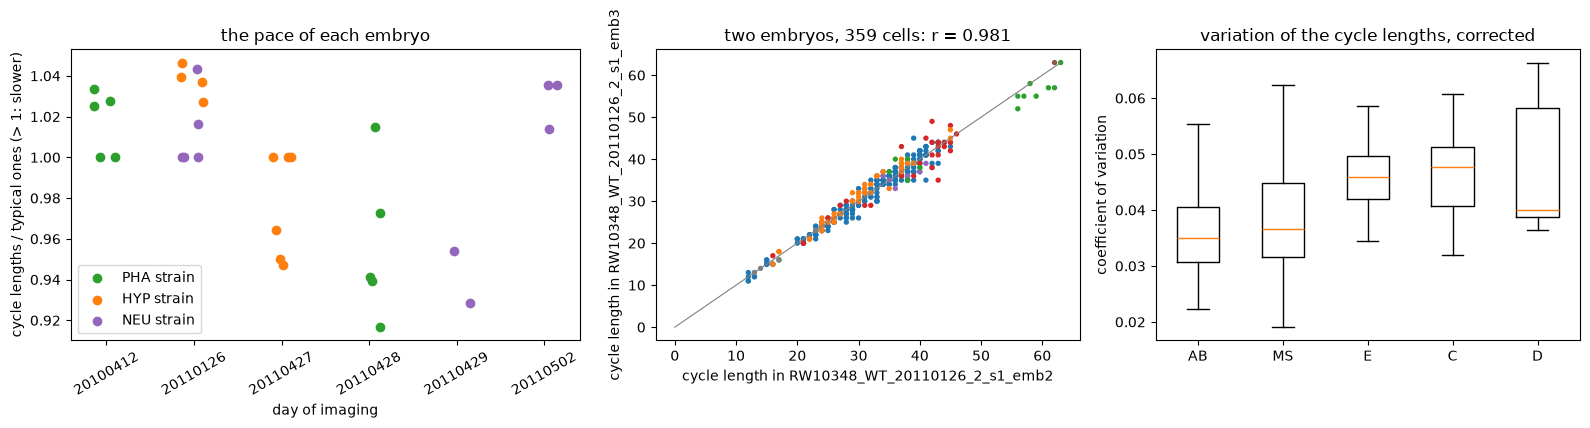

In [42]:
wild_types = {name.replace("info_ZD_", "").replace("_edited", ""): lT  # shorter names
              for name, lT in LineageTreeManager.load(ct.fetch("C.elegans_wild_types"))}
cycles_wt = {name: ct.cycle_lengths(lT) for name, lT in wild_types.items()}
typical = ct.typical_cycles(cycles_wt)  # cells measured in at least 10 embryos -> median cycle
speed = {name: ct.pace(cycles, typical) for name, cycles in cycles_wt.items()}

cells = [c for c in typical if typical[c] >= 8]  # cycles long enough to be measured precisely
cv_raw, cv = ct.cycle_variation(cycles_wt, cells), ct.cycle_variation(cycles_wt, cells, speed)
print(f"{len(wild_types)} embryos; speed between {min(speed.values()):.2f} and {max(speed.values()):.2f}")
print(f"median variation of a cycle length across embryos: {np.median(list(cv_raw.values())):.1%}, "
      f"{np.median(list(cv.values())):.1%} once corrected for the speed of each embryo")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), width_ratios=(1.2, 1, 1))
date = {name: next(p for p in name.split("_") if p.startswith("20")) for name in wild_types}
dates = sorted(set(date.values()))
jitter = np.random.default_rng(0)
for reporter, colour in TISSUES.items():
    names = [n for n, lT in wild_types.items() if lT.reporter == reporter]
    axes[0].scatter([dates.index(date[n]) + jitter.uniform(-0.15, 0.15) for n in names],
                    [speed[n] for n in names], color=colour, label=f"{reporter} strain")
axes[0].set_xticks(range(len(dates)), dates, rotation=30)
axes[0].set(xlabel="day of imaging", ylabel="cycle lengths / typical ones (> 1: slower)",
            title="the pace of each embryo")
axes[0].legend()

a, b = list(cycles_wt)[:2]
common = sorted(set(cycles_wt[a]) & set(cycles_wt[b]))
x, y = np.array([[cycles_wt[a][c], cycles_wt[b][c]] for c in common]).T
axes[1].scatter(x, y, s=8, color=[FOUNDERS.get(ct.founder(c), "grey") for c in common])
axes[1].plot([0, x.max()], [0, x.max()], color="grey", lw=0.8)
axes[1].set(xlabel=f"cycle length in {a}", ylabel=f"cycle length in {b}",
            title=f"two embryos, {len(common)} cells: r = {np.corrcoef(x, y)[0, 1]:.3f}")

per_founder = {f: [v for c, v in cv.items() if ct.founder(c) == f] for f in FOUNDERS}
per_founder = {f: v for f, v in per_founder.items() if len(v) >= 3}
axes[2].boxplot(list(per_founder.values()), showfliers=False)
axes[2].set_xticks(range(1, len(per_founder) + 1), list(per_founder))
axes[2].set(ylabel="coefficient of variation", title="variation of the cycle lengths, corrected")
fig.tight_layout()
print("most variable cells:", ", ".join(f"{c} {cv[c]:.0%}" for c in sorted(cv, key=cv.get)[-5:]))
paces = np.array([speed[n] for n in wild_types])
of_day = np.array([np.mean([speed[m] for m in wild_types if date[m] == date[n]]) for n in wild_types])
print(f"the day of imaging explains {1 - np.var(paces - of_day) / np.var(paces):.0%} of the variance of the pace")

In [43]:
# are the asymmetries of case studies 12 and 13 found in every embryo?
for gen in (5, 6, 7):
    lag = np.array([ct.division_time(lT, "ABpr", gen) - ct.division_time(lT, "ABpl", gen)
                    for lT in wild_types.values()])
    lag = lag[~np.isnan(lag)]
    print(f"generation {gen}: ABpl divides before ABpr in {np.mean(lag > 0):.0%} of {len(lag)} embryos "
          f"(by {np.mean(lag):.1f} time points on average)")

p_first, a_first_ms = [], []
for cycles in cycles_wt.values():
    # cycle(p) - cycle(a) for every pair of a/p sisters, keyed by the name of the a sister
    pairs = {c: cycles[c[:-1] + "p"] - cycles[c] for c in cycles if c.endswith("a") and c[:-1] + "p" in cycles}
    ab = np.array([d for c, d in pairs.items() if c.startswith("AB") and len(c) - 2 in (6, 7)])
    ms = np.array([d for c, d in pairs.items() if c.startswith("MS")])
    p_first.append(np.mean(ab < 0))
    a_first_ms.append(np.mean(ms > 0))
print(f"AB, generations 6-7: the p sister divides first in {min(p_first):.0%} to {max(p_first):.0%} "
      f"of the pairs, depending on the embryo")
print(f"MS: the a sister divides first in {min(a_first_ms):.0%} to {max(a_first_ms):.0%} of the pairs")

generation 5: ABpl divides before ABpr in 90% of 30 embryos (by 0.6 time points on average)
generation 6: ABpl divides before ABpr in 90% of 30 embryos (by 1.0 time points on average)
generation 7: ABpl divides before ABpr in 80% of 30 embryos (by 1.0 time points on average)
AB, generations 6-7: the p sister divides first in 58% to 72% of the pairs, depending on the embryo
MS: the a sister divides first in 67% to 85% of the pairs


Development is very reproducible. The 30 embryos differ in pace by up to
8%, and the day of imaging explains two thirds of these differences, as
expected if the pace is set by the conditions of the day, such as the
temperature. Once the pace is corrected, the length of a cell cycle varies
by less than 4% from one embryo to the next, and the cycle lengths of two
embryos are almost perfectly correlated. P4 and a few MS cells are the most
variable.

The asymmetries found in our single embryo are general. ABpl divides
before ABpr in 80 to 90% of the embryos, by about one time point. In every
embryo, the posterior AB sisters of generations 6 and 7 tend to divide
first, and so do the anterior MS sisters.

### Program or noise?

Case study 12 asked whether the AB divisions drift apart by accumulating
noise. With 30 embryos the question can be answered directly. At each
generation, the "lateness" of a cell is its time of division minus the mean
time of division of its generation, in its embryo (corrected for the pace
of the embryo). If the asynchrony were noise, a cell that is late in one
embryo would not be late in another one. Splitting the variance of the
lateness into a part shared by all embryos (the identity of the cell: the
program) and a part that varies between embryos (the noise) gives the
share of the asynchrony that is reproducible: its intraclass correlation.

generation 3: spread 0.4 time points, of which noise 0.3; share reproducible across embryos 26%
generation 4: spread 0.8 time points, of which noise 0.6; share reproducible across embryos 48%
generation 5: spread 1.3 time points, of which noise 0.8; share reproducible across embryos 60%
generation 6: spread 2.8 time points, of which noise 1.2; share reproducible across embryos 81%
generation 7: spread 5.1 time points, of which noise 1.8; share reproducible across embryos 87%


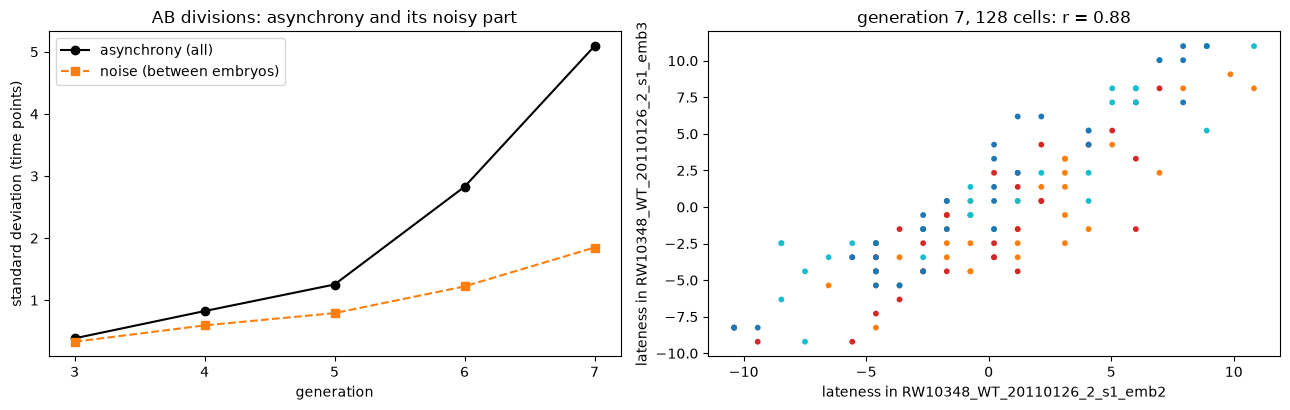

In [44]:
lateness = defaultdict(lambda: defaultdict(dict))  # generation -> cell -> embryo -> lateness
for name, lT in wild_types.items():
    division = ct.ab_division_times(lT)
    for gen in range(3, 8):
        cells_gen = [c for c in division if len(c) - 2 == gen]
        if len(cells_gen) >= 0.9 * 2 ** gen:  # this generation is (almost) complete
            mean = np.mean([division[c] for c in cells_gen])
            for c in cells_gen:
                lateness[gen][c][name] = (division[c] - mean) / speed[name]

gens, total, noise, shared = [], [], [], []
for gen, per_cell in lateness.items():
    values = [list(v.values()) for v in per_cell.values() if len(v) >= 10]
    within = np.mean([np.var(v, ddof=1) for v in values])  # same cell, different embryos
    k = np.mean([len(v) for v in values])
    between = max(np.var([np.mean(v) for v in values], ddof=1) - within / k, 0)  # differences between cells
    gens.append(gen)
    total.append(np.sqrt(between + within))
    noise.append(np.sqrt(within))
    shared.append(between / (between + within))
    print(f"generation {gen}: spread {total[-1]:.1f} time points, of which noise {noise[-1]:.1f}; "
          f"share reproducible across embryos {shared[-1]:.0%}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(gens, total, "o-", color="black", label="asynchrony (all)")
ax1.plot(gens, noise, "s--", color="tab:orange", label="noise (between embryos)")
ax1.set(xlabel="generation", ylabel="standard deviation (time points)",
        title="AB divisions: asynchrony and its noisy part")
ax1.set_xticks(gens)
ax1.legend()
a, b = list(wild_types)[:2]
common = [c for c in lateness[7] if a in lateness[7][c] and b in lateness[7][c]]
x, y = np.array([[lateness[7][c][a], lateness[7][c][b]] for c in common]).T
ax2.scatter(x, y, s=10, color=[QUARTERS.get(c[:4], "grey") for c in common])
ax2.set(xlabel=f"lateness in {a}", ylabel=f"lateness in {b}",
        title=f"generation 7, {len(common)} cells: r = {np.corrcoef(x, y)[0, 1]:.2f}")
fig.tight_layout()

The answer depends on the generation. At generation 3, the small
asynchrony is noise: a cell that divides early in one embryo is not early
in another. From generation 5 on, most of it is programmed: at generation
7, 87% of the variance of the lateness is shared by all the embryos, and
the lateness of the same 128 cells in two embryos is strongly correlated
(each colour is one of the four AB sublineages of case study 12). The noise
grows too, but slowly, about as accumulated independent errors would.

## 23. A screen read from the lineage trees

The same lab knocked down 204 genes by RNAi, with about six embryos per
gene ([Du et al. 2015](https://doi.org/10.1016/j.devcel.2015.07.014)).
Without looking at the reporters, can the lineage trees alone tell which
lineage each gene acts on? For each embryo and each founder lineage (ABa,
ABp, MS, E, C and D), `cross_lineage_edit_distance` compares the lineage
over the 80 time points that follow the birth of its founder with the same
lineage in the 10 wild-type embryos of the same reporter strain. The score
of a gene in a lineage is the median distance of its embryos to the wild
types, divided by the median distance between two wild types: 1 means as
different from the wild type as two wild types are from each other.

The screen, a `LineageTreeManager` of the 1,322 embryos, is downloaded
once (112 MB); running the 80,000 comparisons takes a few minutes.

In [45]:
LINEAGES, DURATION = ["ABa", "ABp", "MS", "E", "C", "D"], 80
screen = LineageTreeManager()  # the wild types and the knockdown embryos
reporter_of, gene_of = {}, {}
for name, lT in wild_types.items():
    screen.add(lT, name)
    reporter_of[name], gene_of[name] = lT.reporter, "wild type"
for name, lT in LineageTreeManager.load(ct.fetch("C.elegans_RNAi_screen")):
    screen.add(lT, name)
    reporter_of[name], gene_of[name] = lT.reporter, lT.gene
trees = dict(screen)
for lT in trees.values():
    lT.time_resolution = 1

root = {}  # (embryo, lineage) -> first node of the founder cell, if followed long enough
for name, lT in trees.items():
    for lineage in LINEAGES:
        first = next((c[0] for c in lT.all_chains if lT.labels[c[0]] == lineage), None)
        if first is not None and lT.time[first] + DURATION <= lT.t_e:
            root[name, lineage] = first

reference = {}  # median distance between two wild types of the same strain
embryo_score = {}  # (embryo, lineage) -> median distance to the wild types / reference
with warnings.catch_warnings():  # the manager keeps the alignments; cleared after each embryo
    warnings.filterwarnings("ignore", message="More than 100 comparisons")
    for lineage in LINEAGES:
        reference[lineage] = np.median([ct.founder_distance(screen, root, a, b, lineage, DURATION)
                                        for a, b in itertools.combinations(wild_types, 2)
                                        if reporter_of[a] == reporter_of[b]])
    for name in trees:
        if gene_of[name] == "wild type":
            continue
        same_strain = [w for w in wild_types if reporter_of[w] == reporter_of[name]]
        for lineage in LINEAGES:
            if (name, lineage) in root:
                d = [ct.founder_distance(screen, root, name, w, lineage, DURATION)
                     for w in same_strain if (w, lineage) in root]
                embryo_score[name, lineage] = np.median(d) / reference[lineage]
        screen.clear_comparisons()
gene_score = defaultdict(dict)  # gene -> lineage -> median score of its embryos
for gene in sorted(set(gene_of.values()) - {"wild type"}):
    for lineage in LINEAGES:
        s = [v for (name, lin), v in embryo_score.items() if lin == lineage and gene_of[name] == gene]
        if s:
            gene_score[gene][lineage] = np.median(s)
print(f"{len(trees) - len(wild_types)} knockdown embryos of {len(gene_score)} genes compared with "
      f"{len(wild_types)} wild types")

1322 knockdown embryos of 204 genes compared with 30 wild types


the most lineage-specific genes:
  LIT-1      E   score  7.3, 8.0 times its other lineages
  PAR-2      E   score  8.4, 7.7 times its other lineages
  MEX-3      D   score 12.8, 6.9 times its other lineages
  SKN-1      E   score  6.3, 5.8 times its other lineages
  PIE-1      D   score  6.2, 5.1 times its other lineages
  PAR-6      D   score  6.1, 4.6 times its other lineages
  CDK-9      D   score  7.7, 4.2 times its other lineages
  C07A9.2    D   score  7.2, 3.7 times its other lineages
  D1054.14   D   score  7.0, 3.6 times its other lineages
  POS-1      E   score  6.9, 3.5 times its other lineages
  TSR-1      E   score  4.9, 3.4 times its other lineages
  SAP-49     E   score  6.6, 3.3 times its other lineages


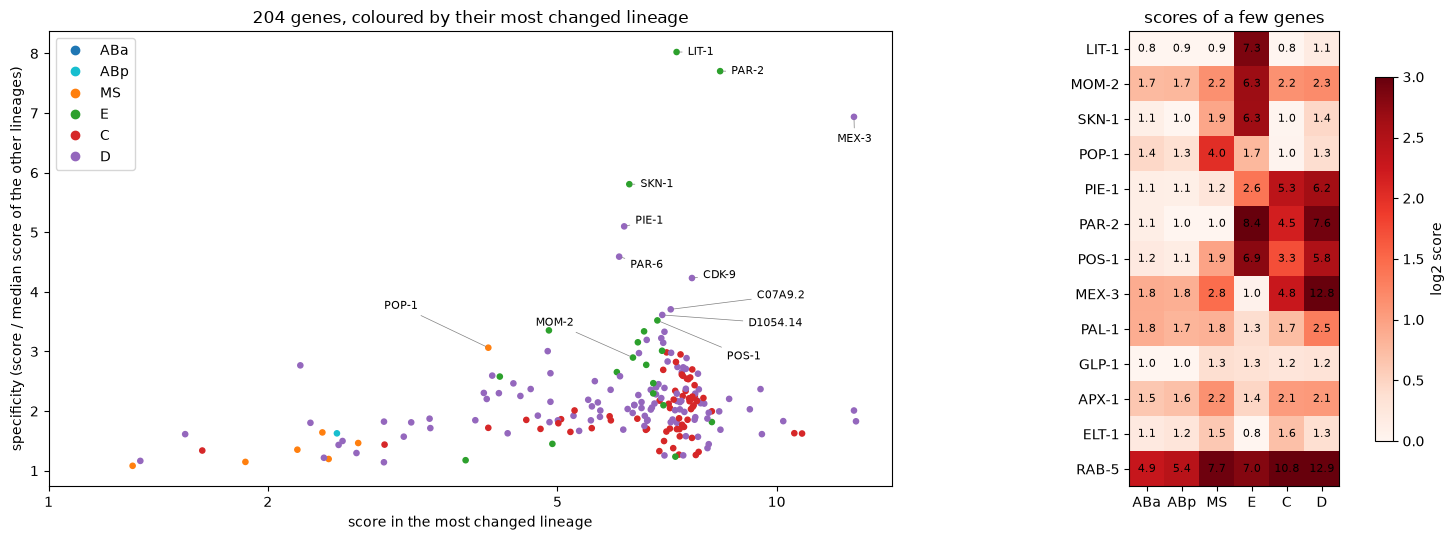

In [46]:
# how strong is the strongest effect of a gene, and how specific to one lineage?
strongest, specificity, target = {}, {}, {}
for gene, scores in gene_score.items():
    if len(scores) < len(LINEAGES):
        continue
    values = np.array([scores[lin] for lin in LINEAGES])
    top = values.argmax()
    strongest[gene], target[gene] = values[top], LINEAGES[top]
    specificity[gene] = values[top] / np.median(np.delete(values, top))

LINEAGE_COLOURS = dict(zip(LINEAGES, ("tab:blue", "tab:cyan", "tab:orange", "tab:green", "tab:red", "tab:purple"),
                           strict=True))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), width_ratios=(1.2, 1))
genes = list(strongest)
ax1.scatter([strongest[g] for g in genes], [specificity[g] for g in genes], s=14,
            color=[LINEAGE_COLOURS[target[g]] for g in genes])
LABELS = {"LIT-1": (8, 0), "PAR-2": (8, 0), "MEX-3": (-12, -16), "SKN-1": (8, 0), "PIE-1": (8, 4),
          "PAR-6": (8, -6), "CDK-9": (8, 2), "POS-1": (50, -26), "C07A9.2": (62, 10), "D1054.14": (62, -6),
          "MOM-2": (-70, 25), "POP-1": (-75, 30)}  # offsets of the labels, in points
for g, offset in LABELS.items():
    if g in strongest:
        ax1.annotate(g, (strongest[g], specificity[g]), xytext=offset, textcoords="offset points",
                     fontsize=8, va="center", arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
ax1.set_xscale("log")
ax1.set_xticks([1, 2, 5, 10], ["1", "2", "5", "10"])
ax1.minorticks_off()
ax1.set(xlabel="score in the most changed lineage",
        ylabel="specificity (score / median score of the other lineages)",
        title=f"{len(genes)} genes, coloured by their most changed lineage")
ax1.legend(handles=[plt.Line2D([], [], ls="", marker="o", color=c, label=lin) for lin, c in LINEAGE_COLOURS.items()])

SELECTED = ["LIT-1", "MOM-2", "SKN-1", "POP-1", "PIE-1", "PAR-2", "POS-1", "MEX-3", "PAL-1",
            "GLP-1", "APX-1", "ELT-1", "RAB-5"]
SELECTED = [g for g in SELECTED if g in gene_score]
table = np.array([[gene_score[g].get(lin, np.nan) for lin in LINEAGES] for g in SELECTED])
im = ax2.imshow(np.log2(table), cmap="Reds", vmin=0, vmax=3)
ax2.set_xticks(range(len(LINEAGES)), LINEAGES)
ax2.set_yticks(range(len(SELECTED)), SELECTED)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax2.text(j, i, f"{table[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax2, label="log2 score", shrink=0.8)
ax2.set_title("scores of a few genes")
fig.tight_layout()

print("the most lineage-specific genes:")
for g in sorted(genes, key=specificity.get, reverse=True)[:12]:
    print(f"  {g:10} {target[g]:3} score {strongest[g]:4.1f}, {specificity[g]:.1f} times its other lineages")

Ranked by how specifically they change one lineage, the 204 genes put the
classic maternal regulators of the early embryo at the top, found here from
the shape and timing of the lineages alone:

- **LIT-1** changes only E, and **MOM-2** mostly E: MOM-2 is the Wnt that
  P2 sends to EMS, and LIT-1 a kinase that relays the signal, so that E
  makes the gut ([Thorpe et al. 1997](https://doi.org/10.1016/s0092-8674(00)80530-9),
  [Meneghini et al. 1999](https://doi.org/10.1038/21666));
- **SKN-1** changes E, and MS to a lesser extent: it specifies the fates
  of the two daughters of EMS ([Bowerman et al. 1992](https://doi.org/10.1016/0092-8674(92)90078-q));
- **POP-1** changes only MS: without it, MS takes the fate of its sister
  E ([Lin et al. 1995](https://doi.org/10.1016/0092-8674(95)90100-0));
- **PIE-1**, **MEX-3**, **PAR-2** and **POS-1** change C and D, the
  lineages of the posterior blastomere P2, and most of them E as well.

Below them come less studied genes, such as C07A9.2 and D1054.14:
candidates for a closer look.

Genes needed by all cells, such as the endocytosis regulator RAB-5, change
every lineage. GLP-1, the Notch receptor of case study 15, changes none,
and APX-1, its ligand, all of them a little: Notch switches fates without
changing the shape and timing of the lineages. The next case study looks
at both kinds of changes.

### Adding the reporters to the screen

GLP-1 and APX-1 change no lineage, yet they change fates (case study 24
shows it with the reporters). The distance of case study 19, which adds the
reporters to the timing, can see such changes. Here it is applied to the
embryos of the pharynx strain: each embryo's reporter is z-scored over all
its nodes, and the ABa and ABp lineages are compared until the end of the
shortest recording, since the reporter comes on late in AB. The scores are
computed as above, with the timing alone and with the reporter.

GLP-1  ABa: 1.2 -> 1.8  ABp: 1.2 -> 1.5
APX-1  ABa: 1.8 -> 1.8  ABp: 1.5 -> 3.4
PIE-1  ABa: 1.0 -> 1.6  ABp: 1.0 -> 2.5
SKN-1  ABa: 0.9 -> 2.1  ABp: 1.0 -> 2.4
POP-1  ABa: 1.1 -> 1.6  ABp: 1.1 -> 1.4
LIT-1  ABa: 1.9 -> 2.0  ABp: 2.9 -> 3.4
MEX-3  ABa: 2.4 -> 2.7  ABp: 2.4 -> 2.7
PAL-1  ABa: 1.5 -> 1.6  ABp: 1.3 -> 1.6


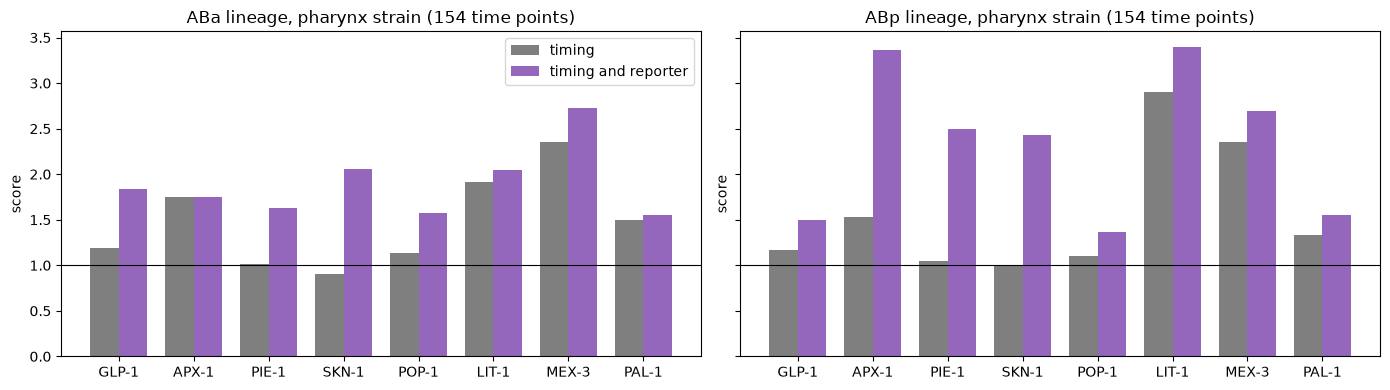

In [47]:
GENES_FATE = ["GLP-1", "APX-1", "PIE-1", "SKN-1", "POP-1", "LIT-1", "MEX-3", "PAL-1"]
pha_embryos = [n for n in trees if reporter_of[n] == "PHA" and gene_of[n] in ("wild type", *GENES_FATE)]
pha_wild_types = [n for n in pha_embryos if gene_of[n] == "wild type"]
for name in pha_embryos:  # the reporter of each embryo, z-scored over the embryo
    lT = trees[name]
    values = np.array([lT.expression[n] for n in lT.nodes], dtype=float)
    lT.reporters = {n: (lT.expression[n] - values.mean()) / values.std() for n in lT.nodes}
founder_node = {(name, lineage): next(c[0] for c in trees[name].all_chains if trees[name].labels[c[0]] == lineage)
                for name in pha_embryos for lineage in ("ABa", "ABp")}
span = {lineage: min(trees[name].t_e - trees[name].time[founder_node[name, lineage]] for name in pha_embryos)
        for lineage in ("ABa", "ABp")}

fate_score = {}  # (style, lineage, gene) -> score
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="More than 100 comparisons")
    for label, style in (("timing", "simple"), ("timing and reporter", ct.SimpleWithReporters)):
        for lineage in ("ABa", "ABp"):
            reference_distance = np.median([ct.founder_distance(screen, founder_node, a, b, lineage, span[lineage], style)
                                            for a, b in itertools.combinations(pha_wild_types, 2)])
            screen.clear_comparisons()
            for gene in GENES_FATE:
                embryos = [n for n in pha_embryos if gene_of[n] == gene]
                fate_score[label, lineage, gene] = np.median(
                    [np.median([ct.founder_distance(screen, founder_node, n, w, lineage, span[lineage], style)
                                for w in pha_wild_types]) for n in embryos]
                ) / reference_distance
                screen.clear_comparisons()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, lineage in zip(axes, ("ABa", "ABp"), strict=True):
    for k, (label, colour) in enumerate((("timing", "tab:grey"), ("timing and reporter", "tab:purple"))):
        ax.bar(np.arange(len(GENES_FATE)) + 0.38 * (k - 0.5), [fate_score[label, lineage, g] for g in GENES_FATE],
               width=0.38, color=colour, label=label)
    ax.axhline(1, color="black", lw=0.8)
    ax.set_xticks(range(len(GENES_FATE)), GENES_FATE)
    ax.set(title=f"{lineage} lineage, pharynx strain ({span[lineage]} time points)", ylabel="score")
axes[0].legend()
fig.tight_layout()
for gene in GENES_FATE:
    print(f"{gene:6}", "  ".join(f"{lineage}: {fate_score['timing', lineage, gene]:.1f} -> "
                                 f"{fate_score['timing and reporter', lineage, gene]:.1f}" for lineage in ("ABa", "ABp")))

With the reporter, knockdowns that leave the shape and timing of AB
unchanged stand out. In the APX-1 and PIE-1 knockdowns, the score of the
ABp lineage goes from 1.5 and 1.0 with the timing alone to 3.4 and 2.5: P2
no longer induces ABp, which develops like its sister ABa and makes
pharynx ([Mango et al. 1994](https://doi.org/10.1242/dev.120.8.2305)).
In the GLP-1 and SKN-1 knockdowns, ABa moves away from the wild type too
(1.2 to 1.8, and 0.9 to 2.1), as it loses the pharynx that MS induces.
Timing and fate are two views of the same lineage, and one distance can
carry both.

## 24. Fate transformations, in the trees and in the reporters

What do these scores mean? When a gene specifies the fate of a cell, its
knockdown often makes the cell adopt the fate of another one, with that
cell's pace of division. In *lit-1* knockdowns, E is expected to divide like
MS, and in *pop-1* knockdowns, MS like E. Here are the E and MS lineages of
a wild-type embryo and of the knockdown embryo with the median score, over
the 80 time points of the screen.

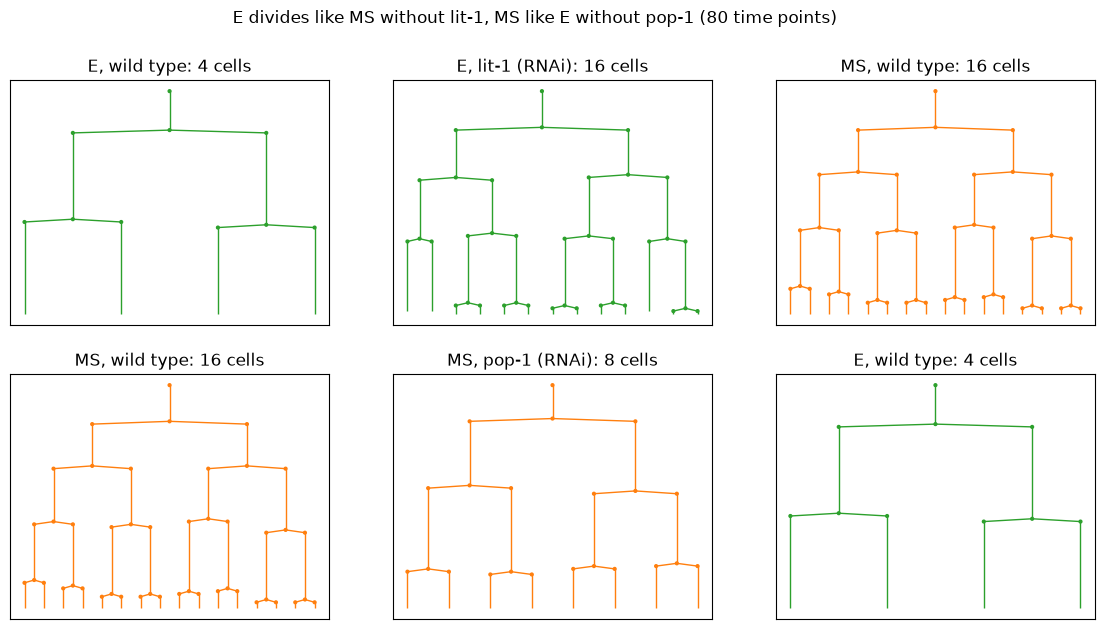

In [48]:
wt = min(wild_types, key=lambda name: abs(speed[name] - 1))  # a wild type of typical pace
panels = [(wt, "E", "wild type"), (ct.typical_embryo(embryo_score, gene_of, "LIT-1", "E"), "E", "lit-1 (RNAi)"),
          (wt, "MS", "wild type"), (wt, "MS", "wild type"),
          (ct.typical_embryo(embryo_score, gene_of, "POP-1", "MS"), "MS", "pop-1 (RNAi)"), (wt, "E", "wild type")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (name, lineage, label) in zip(axes.flat, panels, strict=True):
    lT, first = trees[name], root[name, lineage]
    lT.plot_subtree(first, end_time=lT.time[first] + DURATION, ax=ax, size=4, lw=1,
                    default_color=LINEAGE_COLOURS[lineage])
    n_cells = len(lT.nodes_at_t(lT.time[first] + DURATION, first))
    ax.set_title(f"{lineage}, {label}: {n_cells} cells")
fig.suptitle("E divides like MS without lit-1, MS like E without pop-1 (80 time points)");

Ea and Ep    wild type  median cycle  33.0 (60 cells)
Ea and Ep    LIT-1      median cycle  16.8 (12 cells)
Ea and Ep    MOM-2      median cycle  21.6 (16 cells)
Ea and Ep    POP-1      median cycle  29.5 (12 cells)
Ea and Ep    SKN-1      median cycle  24.3 (14 cells)
Ea and Ep    GLP-1      median cycle  30.9 (16 cells)
Ea and Ep    APX-1      median cycle  33.0 (16 cells)
MSa and MSp  wild type  median cycle  16.4 (60 cells)
MSa and MSp  LIT-1      median cycle  15.3 (12 cells)
MSa and MSp  MOM-2      median cycle  16.7 (16 cells)
MSa and MSp  POP-1      median cycle  24.3 (12 cells)
MSa and MSp  SKN-1      median cycle  17.8 (14 cells)
MSa and MSp  GLP-1      median cycle  15.3 (16 cells)
MSa and MSp  APX-1      median cycle  16.4 (16 cells)


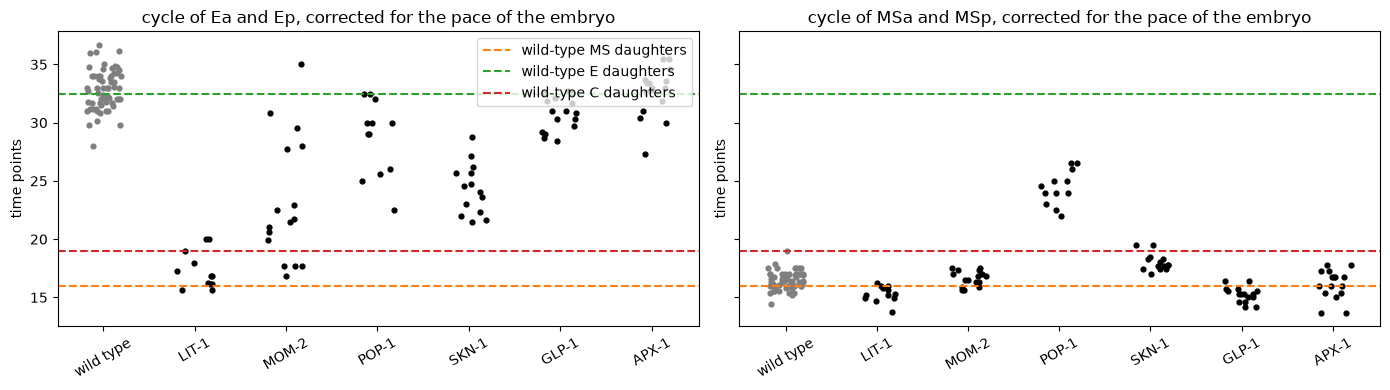

In [49]:
GROUPS = {"wild type": list(wild_types.values())}
for gene in ("LIT-1", "MOM-2", "POP-1", "SKN-1", "GLP-1", "APX-1"):
    GROUPS[gene] = [trees[name] for name in trees if gene_of[name] == gene]
rhythm = {"MS": np.median([typical["MSa"], typical["MSp"]]), "E": np.median([typical["Ea"], typical["Ep"]]),
          "C": np.median([typical["Ca"], typical["Cp"]])}

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (daughters_of, title) in zip(axes, ((("Ea", "Ep"), "Ea and Ep"), (("MSa", "MSp"), "MSa and MSp")), strict=True):
    for i, (group, embryos) in enumerate(GROUPS.items()):
        values = []
        for lT in embryos:
            cycles = ct.corrected_cycles(lT, typical)  # divided by the pace of the embryo
            values += [cycles[c] for c in daughters_of if c in cycles]
        ax.scatter(i + jitter.uniform(-0.2, 0.2, len(values)), values, s=12, color="tab:grey" if i == 0 else "black")
        print(f"{title:12} {group:10} median cycle {np.median(values):5.1f} ({len(values)} cells)")
    for lineage, colour in (("MS", "tab:orange"), ("E", "tab:green"), ("C", "tab:red")):
        ax.axhline(rhythm[lineage], color=colour, ls="--", label=f"wild-type {lineage} daughters")
    ax.set_xticks(range(len(GROUPS)), list(GROUPS), rotation=30)
    ax.set(title=f"cycle of {title}, corrected for the pace of the embryo", ylabel="time points")
axes[0].legend(loc="upper right")
fig.tight_layout()

The trees and the cycle lengths show the transformations. In 80 time
points, the E lineage of the *lit-1* embryo makes 16 cells, as many as a
wild-type MS lineage, against 4 for a wild-type E; and the MS lineage of
the *pop-1* embryo makes 8 cells instead of 16.

- Without LIT-1, the E daughters divide at the pace of the MS daughters,
  twice as fast as normal: E takes the fate of MS. Without MOM-2, they
  speed up too.
- Without POP-1, the MS daughters slow down towards the pace of E: MS takes
  the fate of E ([Lin et al. 1995](https://doi.org/10.1016/0092-8674(95)90100-0)).
- Without SKN-1, the E daughters speed up towards the pace of the C
  daughters: in *skn-1* mutants, EMS produces the hypodermis and muscle of
  the C lineage ([Bowerman et al. 1992](https://doi.org/10.1016/0092-8674(92)90078-q)).
- GLP-1 and APX-1, which act in AB, leave E and MS unchanged.

The reporters tell the other half of the story, since knockdowns can change
fates without changing the lineage. Below, the change of each reporter in
each sublineage, against the wild types of the same strain (the mean
z-score over the last 30 time points of each embryo).

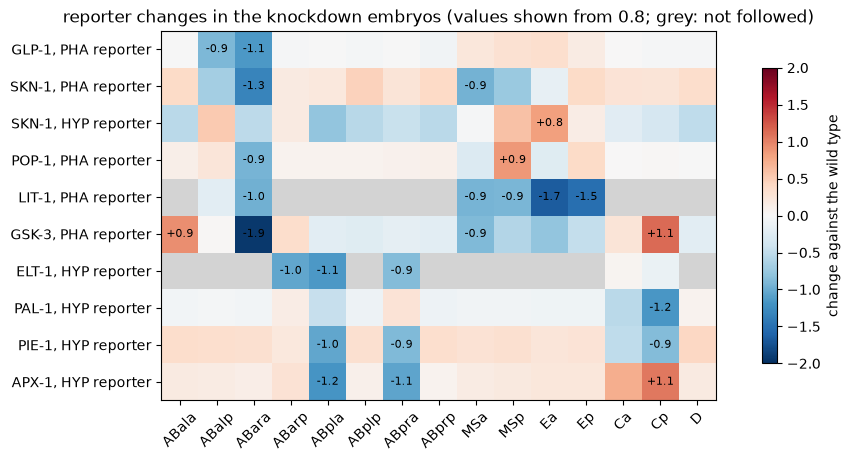

In [50]:
SUBLINEAGES_SCREEN = SUBLINEAGES_KD
wt_profile = {r: np.nanmean([ct.reporter_profile(lT, SUBLINEAGES_SCREEN) for lT in wild_types.values()
                             if lT.reporter == r], axis=0)
              for r in TISSUES}
ROWS = [("GLP-1", "PHA"), ("SKN-1", "PHA"), ("SKN-1", "HYP"), ("POP-1", "PHA"), ("LIT-1", "PHA"),
        ("GSK-3", "PHA"), ("ELT-1", "HYP"), ("PAL-1", "HYP"), ("PIE-1", "HYP"), ("APX-1", "HYP")]
with warnings.catch_warnings():  # some sublineages were not followed to the end in some embryos
    warnings.simplefilter("ignore", RuntimeWarning)
    change = np.array([np.nanmean([ct.reporter_profile(trees[name], SUBLINEAGES_SCREEN) for name in trees
                                   if gene_of[name] == gene and reporter_of[name] == reporter], axis=0)
                       - wt_profile[reporter] for gene, reporter in ROWS])

fig, ax = plt.subplots(figsize=(12, 4.8))
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("lightgrey")
im = ax.imshow(np.ma.masked_invalid(change), cmap=cmap, vmin=-2, vmax=2)
ax.set_xticks(range(len(SUBLINEAGES_SCREEN)), SUBLINEAGES_SCREEN, rotation=45)
ax.set_yticks(range(len(ROWS)), [f"{gene}, {reporter} reporter" for gene, reporter in ROWS])
for i in range(change.shape[0]):
    for j in range(change.shape[1]):
        if abs(change[i, j]) >= 0.8:
            ax.text(j, i, f"{change[i, j]:+.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="change against the wild type", shrink=0.8)
ax.set_title("reporter changes in the knockdown embryos (values shown from 0.8; grey: not followed)");

Each row matches a known role of the gene:

- **GLP-1**, the Notch receptor: ABalp and ABara lose the pharynx reporter.
  They are the two cells that MS induces at the 12-cell stage (case study
  15).
- **SKN-1**: MS loses the pharynx reporter and E gains the hypodermis
  reporter, as the EMS lineage takes the fate of C. ABara loses the pharynx
  reporter too: the MS cell that should induce it is transformed. Same for
  **POP-1**, where MSp gains the reporter of its sister, the gut precursor E.
- **LIT-1**, needed in the posterior daughters of a/p divisions: the
  reporter is lost from E, MS and ABara.
- **GSK-3**: the C lineage gains the pharynx reporter, as in the knockdown
  mapped onto our embryo (case study 21).
- **ELT-1**, a GATA factor needed for the hypodermis: three hypodermal
  sublineages lose the hypodermis reporter; **PAL-1**, needed for the C and D
  lineages: Cp loses it.
- **APX-1**, the Notch ligand of P2, and **PIE-1**, which keeps P2 a
  germline cell: ABpla and ABpra lose the hypodermis reporter. In both
  cases P2 no longer induces ABp, which develops like its sister ABa
  ([Mango et al. 1994](https://doi.org/10.1242/dev.120.8.2305)).

## Where to go next

- The API reference lists every method of `LineageTree` and
  `LineageTreeManager`.
- `lineage_tree_examples.ipynb` compares two embryos cell by cell to find
  when and where a phenotype appears.
- The napari plugin [napari-relax](https://github.com/GuignardLab/napari-relax)
  explores lineages and their distances interactively.
- `celegans_tools.py` holds the helpers of this notebook, and `data/` its
  datasets: `data/README.md` describes them and how they were made.